# Nettoyage et analyse des déplacements avec PySpark

Enquête de mobilité de Dakar.

Source : `donnees_deplacement_PSpark_2026_1.xlsx`.

Le notebook comprend le nettoyage, l'analyse exploratoire et la prédiction du motif de déplacement.


## Installation dans Google Colab

Exécuter cette cellule au début de chaque session. Elle installe PySpark 3.5.3 et prépare Java si nécessaire.


In [ ]:
# ---- 1. Verifier Java (Spark tourne sur la JVM) -----------------------------
import os # Permet d'interagir avec le systéme
import subprocess #permet de lancer une commande systéme depuis python

def version_java():
    try:
        sortie = subprocess.run(["java", "-version"], capture_output=True, text=True)
        texte = sortie.stderr or sortie.stdout
        for mot in texte.split():
            if '"' in mot:
                return int(mot.strip('"').split(".")[0] if not mot.startswith('"1.')
                           else mot.strip('"').split(".")[1])
    except FileNotFoundError:
        return None
    return None


v = version_java()
if v is None or v < 11:
    print("Installation de Java 17 (environ 40 s)...")
    !apt-get -qq install -y openjdk-17-jdk-headless > /dev/null
    os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"
    v = version_java()
print(f"Java {v} detecte")

# ---- 2. Installer PySpark ---------------------------------------------------
!pip install -q pyspark==3.5.3 openpyxl

import pyspark
print(f"PySpark {pyspark.__version__} installe")

Java 21 detecte
PySpark 3.5.3 installe


## Chargement du fichier Excel

Trois options sont disponibles :

- **Dépôt direct** : sélectionner le fichier Excel depuis l'ordinateur.
- **Google Drive** : décommenter le bloc B et adapter le chemin dans `MyDrive/`.
- **Fichier présent dans Colab** : déposer le fichier dans le panneau Fichiers.


In [ ]:
import glob # glob sert à rechercher des fichiers à partir d’un chemin ou d’un motif.
import os

NOM_FICHIER = "donnees_deplacement_PSpark_2026_1.xlsx"


def chercher():
    """Cherche le fichier dans les emplacements habituels de Colab."""
    for motif in [NOM_FICHIER, f"/content/{NOM_FICHIER}",
                  f"/content/drive/MyDrive/{NOM_FICHIER}",
                  f"/content/drive/MyDrive/**/{NOM_FICHIER}",
                  f"/content/**/{NOM_FICHIER}"]:
        trouves = glob.glob(motif, recursive=True)
        if trouves:
            return trouves[0]
    return None


chemin = chercher()

# B. Google Drive (decommenter ces deux lignes pour l'utiliser)
# from google.colab import drive
# drive.mount('/content/drive')

#  A. Depot direct depuis l'ordinateur
if chemin is None:
    try:
        from google.colab import files
        print(f"Selectionnez {NOM_FICHIER} ...")
        depot = files.upload()
        chemin = list(depot.keys())[0]
    except ImportError:
        pass   # hors Colab : le fichier est suppose present

chemin = chemin or chercher()
assert chemin, (f"{NOM_FICHIER} introuvable. Deposez-le via le panneau Fichiers "
                f"(icone dossier a gauche) ou montez votre Drive.")

FICHIER_XLSX = chemin
print(f"Fichier trouve : {FICHIER_XLSX} "
      f"({os.path.getsize(FICHIER_XLSX) / 1e6:.1f} Mo)")

Selectionnez donnees_deplacement_PSpark_2026_1.xlsx ...


Saving donnees_deplacement_PSpark 2026.xlsx to donnees_deplacement_PSpark 2026 (3).xlsx
Fichier trouve : donnees_deplacement_PSpark 2026 (3).xlsx (7.8 Mo)


In [ ]:
import os
import shutil

import pandas as pd
from pyspark.sql import SparkSession, DataFrame, Window # creer la session # représenter une table dans spark#window effectuer des calculs par groupe en conservants les lignes indiv
from pyspark.sql import functions as F
from pyspark.sql.types import StructType, StructField, IntegerType, DoubleType, StringType

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

# ---- Chemins -----------------------------------------------------------------
# FICHIER_XLSX a ete defini par la cellule de chargement ci-dessus.
# Sur Colab tout vit dans /content, efface a la deconnexion : les sorties sont
# telechargees a la fin du notebook (derniere cellule).
DOSSIER_CSV = "/content/donnees_csv"
DOSSIER_SORTIE = "/content/sortie"

print(f"Source  : {FICHIER_XLSX}")
print(f"Sorties : {DOSSIER_SORTIE}")

print("PySpark pret.")

Source  : donnees_deplacement_PSpark 2026 (3).xlsx
Sorties : /content/sortie
PySpark pret.


## Paramètres de nettoyage


In [ ]:
# Codes de strate qui ne designent pas une zone reelle : "non affecte"
CODES_STRATE_INVALIDES = ["NA_d", "NA_g", "NA_p", "NA_region", "NA1_r"]
CODE_HORS_PERIMETRE = "zex"          # zone exterieure a l'agglomeration

# Valeurs sentinelles du questionnaire signifiant "non renseigne"
SENTINELLES_COUT = [99999.0, 9999.0, -1.0]

# Bornes de plausibilite
AGE_MIN, AGE_MAX = 5, 110
DUREE_MIN, DUREE_MAX = 1, 1440       # plafond de controle provisoire (24 h)
SEUIL_DUREE_ATYPIQUE = 600           # >10 h : signalement, pas rejet automatique
TOLERANCE_DUREE_MN = 5               # ecart admis duree declaree vs calculee
HEURE_MAX_H = 31                     # 3130 = 07h30 le lendemain
QUANTILE_WINSOR = 0.995              # seuil de winsorisation du cout

# Departement deduit de la 1re lettre du code strate
DEPARTEMENTS = {"D": "DAKAR", "G": "GUEDIAWAYE", "P": "PIKINE", "R": "RUFISQUE"}

CLE_METIER = ["num_menage", "num_individu", "num_deplacement"]

### Renommage des colonnes

- `Dextination_StrateArrivee` devient `strate_arrivee`.
- Les colonnes `NbTrajets*` deviennent `poids_trajets_*` : elles contiennent des poids par mode et ne doivent pas être interprétées comme des comptages.


In [ ]:
RENOMMAGE = {
    "numMena": "num_menage",
    "num_individu": "num_individu",
    "num_Deplacement": "num_deplacement",
    "Poids_extra": "poids_extra",
    "LieuDepart": "code_quartier_depart",
    "Origine_StrateDepart": "strate_depart",
    "HeureDepart": "heure_depart_hhmm",
    "LieuArrivee": "code_quartier_arrivee",
    "Dextination_StrateArrivee": "strate_arrivee",   # coquille corrigee
    "HeureArrivee": "heure_arrivee_hhmm",
    "Duree (mn)": "duree_mn",
    "Motif": "motif",
    "NbTrajets": "nb_trajets",
    "Mode1": "mode_1",
    "Mode2": "mode_2",
    "Mode3": "mode_3",
    "Mode4": "mode_4",
    "Cout": "cout",
    # /!\ poids d'extrapolation ventile par mode, PAS un nombre de trajets
    "NbTrajetsAPied": "poids_trajets_apied",
    "NbTrajetsAutre": "poids_trajets_autre",
    "NbTrajetsMoto": "poids_trajets_moto",
    "NbTrajetsVoiture": "poids_trajets_voiture",
    "NbTrajetsTaxi": "poids_trajets_taxi",
    "NbTrajetsClando": "poids_trajets_clando",
    "NbTrajetsCarRapide": "poids_trajets_car_rapide",
    "NbTrajetsNN": "poids_trajets_ndiaga_ndiaye",
    "NbTrajetsDDD": "poids_trajets_ddd",
    "NbTrajetsTata": "poids_trajets_tata",
    "Moyen de transport": "moyen_transport",
    "JourEnqueteIndi": "jour_enquete",
    "PositMenage": "position_menage",
    "Age": "age",
    "Sexe": "sexe",
}

COLONNES_POIDS_MODE = [c for c in RENOMMAGE.values() if c.startswith("poids_trajets_")]

# La saisie melange CamelCase et texte libre.
# On n'utilise PAS initcap() : il ecraserait "TravailHabituel" en "Travailhabituel".
MAP_MODES = {
    "Voiture particuliere passager": "VoitureParticulierePassager",
    "Voiture Particuliere Passager": "VoitureParticulierePassager",
    "voiture particuliere passager": "VoitureParticulierePassager",
    "A pied": "APied",
    "Apied": "APied",
}

print(f"{len(RENOMMAGE)} colonnes renommees, dont {len(COLONNES_POIDS_MODE)} colonnes de poids par mode")

33 colonnes renommees, dont 10 colonnes de poids par mode


## Étape 0 - Conversion Excel en CSV

Un CSV intermédiaire est produit avec pandas pour la lecture dans Spark. Les colonnes sont renommées à cette Étape.


In [ ]:
os.makedirs(DOSSIER_CSV, exist_ok=True)

# ---- Table de faits ----------------------------------------------------------
faits = pd.read_excel(FICHIER_XLSX, sheet_name="deplacement").rename(columns=RENOMMAGE)

manquantes = [c for c in RENOMMAGE.values() if c not in faits.columns]
assert not manquantes, f"Colonnes attendues absentes de l'Excel : {manquantes}"

faits = faits[list(RENOMMAGE.values())]
CHEMIN_FAITS = os.path.join(DOSSIER_CSV, "deplacement.csv")
faits.to_csv(CHEMIN_FAITS, index=False, encoding="utf-8")

# ---- Referentiel strate / commune -------------------------------------------
ref_pd = pd.read_excel(FICHIER_XLSX, sheet_name="strate_commune")
ref_pd.columns = ["commune", "code_strate", "code_commune"]
CHEMIN_REF = os.path.join(DOSSIER_CSV, "strate_commune.csv")
ref_pd.to_csv(CHEMIN_REF, index=False, encoding="utf-8")

print(f"Faits        : {len(faits):,} lignes x {faits.shape[1]} colonnes -> {CHEMIN_FAITS}")
print(f"Referentiel  : {len(ref_pd)} communes -> {CHEMIN_REF}")
faits.head(3)

Faits        : 45,605 lignes x 33 colonnes -> /content/donnees_csv/deplacement.csv
Referentiel  : 52 communes -> /content/donnees_csv/strate_commune.csv


,num_menage,num_individu,num_deplacement,poids_extra,code_quartier_depart,strate_depart,heure_depart_hhmm,code_quartier_arrivee,strate_arrivee,heure_arrivee_hhmm,duree_mn,motif,nb_trajets,mode_1,mode_2,mode_3,mode_4,cout,poids_trajets_apied,poids_trajets_autre,poids_trajets_moto,poids_trajets_voiture,poids_trajets_taxi,poids_trajets_clando,poids_trajets_car_rapide,poids_trajets_ndiaga_ndiaye,poids_trajets_ddd,poids_trajets_tata,moyen_transport,jour_enquete,position_menage,age,sexe
0,1,1,1,122.133333,10,D01,815,8,D05,820,5,TravailAmbulant,1,Autre,NaN,NaN,NaN,0.0,0.000000,122.133333,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Autre,Vendredi,ChefMenage,53,Homme
1,1,1,2,122.133333,8,D05,2000,10,D01,2020,20,RetourDomicile,1,MobyletteMotoConducteur,NaN,NaN,NaN,0.0,0.000000,0.000000,122.133333,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Moto,Vendredi,ChefMenage,53,Homme
2,1,2,1,122.133333,10,D01,610,10,D01,615,5,TravailHabituel,1,APied,NaN,NaN,NaN,0.0,122.133333,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,APied,Vendredi,FrereSoeur,30,Femme


## Étape 1 - Session Spark et lecture des données

La lecture utilise un schéma explicite pour définir les types des colonnes.


In [ ]:
spark = (
    SparkSession.builder
    .appName("NettoyageDeplacementsDakar")
    .master("local[*]")                               # Colab : 2 vCPU
    .config("spark.sql.shuffle.partitions", "4")      # petit volume -> peu de partitions
    .config("spark.sql.session.timeZone", "UTC")
    .config("spark.driver.memory", "4g")              # Colab offre ~12 Go de RAM
    .config("spark.ui.showConsoleProgress", "false")  # barres de progression illisibles
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version)

Spark 3.5.3


In [ ]:
SCHEMA_DEPLACEMENT = StructType([ # définition du shéma
    StructField("num_menage", IntegerType(), True),
    StructField("num_individu", IntegerType(), True),
    StructField("num_deplacement", IntegerType(), True),
    StructField("poids_extra", DoubleType(), True),
    StructField("code_quartier_depart", IntegerType(), True),
    StructField("strate_depart", StringType(), True),
    StructField("heure_depart_hhmm", IntegerType(), True),
    StructField("code_quartier_arrivee", IntegerType(), True),
    StructField("strate_arrivee", StringType(), True),
    StructField("heure_arrivee_hhmm", IntegerType(), True),
    StructField("duree_mn", IntegerType(), True),
    StructField("motif", StringType(), True),
    StructField("nb_trajets", IntegerType(), True),
    StructField("mode_1", StringType(), True),
    StructField("mode_2", StringType(), True),
    StructField("mode_3", StringType(), True),
    StructField("mode_4", StringType(), True),
    StructField("cout", DoubleType(), True),
] + [StructField(c, DoubleType(), True) for c in COLONNES_POIDS_MODE] + [
    StructField("moyen_transport", StringType(), True),
    StructField("jour_enquete", StringType(), True),
    StructField("position_menage", StringType(), True),
    StructField("age", IntegerType(), True),
    StructField("sexe", StringType(), True),
])

brut = (
    spark.read
    .option("header", True)#utiliser la premiére lignes comme nom colonne
    .option("mode", "PERMISSIVE")
    .option("nullValue", "")
    .option("nanValue", "NaN")
    .schema(SCHEMA_DEPLACEMENT)
    .csv(CHEMIN_FAITS)
    .cache()# demandé a concerver les donné avant les reutiliser
)

N_BRUT = brut.count()
print(f"{N_BRUT:,} lignes lues, {len(brut.columns)} colonnes")
brut.printSchema()

45,605 lignes lues, 33 colonnes
root
 |-- num_menage: integer (nullable = true)
 |-- num_individu: integer (nullable = true)
 |-- num_deplacement: integer (nullable = true)
 |-- poids_extra: double (nullable = true)
 |-- code_quartier_depart: integer (nullable = true)
 |-- strate_depart: string (nullable = true)
 |-- heure_depart_hhmm: integer (nullable = true)
 |-- code_quartier_arrivee: integer (nullable = true)
 |-- strate_arrivee: string (nullable = true)
 |-- heure_arrivee_hhmm: integer (nullable = true)
 |-- duree_mn: integer (nullable = true)
 |-- motif: string (nullable = true)
 |-- nb_trajets: integer (nullable = true)
 |-- mode_1: string (nullable = true)
 |-- mode_2: string (nullable = true)
 |-- mode_3: string (nullable = true)
 |-- mode_4: string (nullable = true)
 |-- cout: double (nullable = true)
 |-- poids_trajets_apied: double (nullable = true)
 |-- poids_trajets_autre: double (nullable = true)
 |-- poids_trajets_moto: double (nullable = true)
 |-- poids_trajets_voitu

## Étape 2 - Profilage des données


### 2.1 - Valeurs manquantes


In [ ]:
nuls = brut.select([
    F.sum(F.col(c).isNull().cast("int")).alias(c) for c in brut.columns
]).toPandas().T
nuls.columns = ["nb_nuls"]
nuls["pct"] = (100 * nuls["nb_nuls"] / N_BRUT).round(2)
nuls[nuls.nb_nuls > 0].sort_values("nb_nuls", ascending=False)

,nb_nuls,pct
mode_4,45220,99.16
mode_3,42440,93.06
mode_2,37824,82.94
cout,11,0.02
poids_trajets_apied,1,0.00


### 2.2 - Heures après minuit

Les heures sont codées au format entier `HHMM` et peuvent dépasser 24 heures.


In [ ]:
brut.select(
    F.max("heure_depart_hhmm").alias("depart_max"),
    F.max("heure_arrivee_hhmm").alias("arrivee_max"),
    F.sum((F.col("heure_depart_hhmm") > 2400).cast("int")).alias("departs_apres_minuit"),
    F.sum((F.col("heure_arrivee_hhmm") > 2400).cast("int")).alias("arrivees_apres_minuit"),
    F.sum((F.col("heure_depart_hhmm") % 100 >= 60).cast("int")).alias("minutes_invalides_dep"),
    F.sum((F.col("heure_arrivee_hhmm") % 100 >= 60).cast("int")).alias("minutes_invalides_arr"),
).toPandas().T.rename(columns={0: "valeur"})

,valeur
depart_max,2757
arrivee_max,3130
departs_apres_minuit,184
arrivees_apres_minuit,304
minutes_invalides_dep,0
minutes_invalides_arr,3


In [ ]:
# Exemples concrets : 2410 = 00h10 le lendemain
brut.filter(F.col("heure_arrivee_hhmm") > 2400) \
    .select("num_menage", "num_individu", "heure_depart_hhmm", "heure_arrivee_hhmm",
            "duree_mn", "motif") \
    .orderBy(F.desc("heure_arrivee_hhmm")).limit(5).toPandas()

,num_menage,num_individu,heure_depart_hhmm,heure_arrivee_hhmm,duree_mn,motif
0,7541,3,2500,3130,390,Religion
1,6783,3,2700,2900,120,RetourDomicile
2,1601,7,2757,2817,20,RetourDomicile
3,1083,1,2700,2815,75,AchatsNonAlimentaires
4,401,4,2745,2805,20,RetourDomicile


### 2.3 - Codes particuliers et coûts sentinelles

Certaines valeurs renseignées peuvent représenter une information absente. Leur signification doit être vérifiée dans le dictionnaire des variables.


In [ ]:
print("--- Codes de strate observes ---")
strates = (brut.select(F.col("strate_depart").alias("code"))
           .union(brut.select(F.col("strate_arrivee").alias("code")))
           .groupBy("code").count().orderBy("code").toPandas())
print(sorted(strates.code.dropna().unique()))

print("\n--- Codes qui ne sont pas des zones reelles ---")
print(strates[strates.code.isin(CODES_STRATE_INVALIDES + [CODE_HORS_PERIMETRE])]
      .to_string(index=False))

print("\n--- Distribution du cout : la queue haute ---")
brut.select("cout").summary("75%", "95%", "99%", "max").show()
print("Lignes a cout = 99999 (sentinelle) :",
      brut.filter(F.col("cout") == 99999).count())

--- Codes de strate observes ---
['D01', 'D02', 'D03', 'D04', 'D05', 'D06', 'D07', 'D08', 'D09', 'D10', 'D11', 'D12', 'D13', 'D14', 'D15', 'D16', 'D17', 'D18', 'G01', 'G02', 'G03', 'G04', 'G05', 'NA1_r', 'NA_d', 'NA_g', 'NA_p', 'NA_region', 'P01', 'P02', 'P03', 'P04', 'P05', 'P06', 'P07', 'P08', 'P09', 'P10', 'R01', 'R02', 'R03', 'R04', 'R05', 'R06', 'R07', 'R08', 'zex']

--- Codes qui ne sont pas des zones reelles ---
     code  count
    NA1_r     21
     NA_d    128
     NA_g     66
     NA_p     89
NA_region     26
      zex    189

--- Distribution du cout : la queue haute ---
+-------+-------+
|summary|   cout|
+-------+-------+
|    75%|    0.0|
|    95%|  300.0|
|    99%| 1500.0|
|    max|99999.0|
+-------+-------+

Lignes a cout = 99999 (sentinelle) : 1


## étape 3 - Normalisation des chaînes

Les espaces superflus sont supprimés et les chaînes vides deviennent `NULL`.

Les libellés d'origine, comme `TravailHabituel`, sont conservés. Les corrections de modalités sont définies dans `MAP_MODES`. Des clés normalisées sont créées pour regrouper les motifs et les moyens de transport.


In [1]:
def nettoyer_chaines(df: DataFrame) -> DataFrame:
    colonnes_texte = [c for c, t in df.dtypes if t == "string"]

    # trim + espaces multiples + chaine vide -> NULL
    for c in colonnes_texte:
        df = df.withColumn(
            c,
            F.when(F.trim(F.col(c)) == "", None)
             .otherwise(F.regexp_replace(F.trim(F.col(c)), r"\s+", " "))
        )

    # Harmonisation des libelles de mode (mapping explicite)
    for c in ["mode_1", "mode_2", "mode_3", "mode_4"]:
        expression = F.col(c)
        for valeur_brute, valeur_propre in MAP_MODES.items():
            expression = F.when(F.col(c) == F.lit(valeur_brute),
                                F.lit(valeur_propre)).otherwise(expression)
        df = df.withColumn(c, expression)

    # Cle normalisee pour les regroupements
    for c in ["motif", "moyen_transport"]:
        df = df.withColumn(
            f"{c}_cle",
            F.lower(F.regexp_replace(
                F.translate(F.col(c), "àâäéèêëîïôöùûüç", "aaaeeeeiioouuuc"),
                r"[^A-Za-z0-9]", ""))
        )

    # Codes de zone : majuscules, sans espace interne
    for c in ["strate_depart", "strate_arrivee"]:
        df = df.withColumn(c, F.upper(F.regexp_replace(F.col(c), " ", "")))

    return df


df = nettoyer_chaines(brut)
df.select("motif", "motif_cle", "mode_1", "moyen_transport", "strate_depart").limit(5).toPandas()

NameError: name 'DataFrame' is not defined

# Étape 4 — Codes particuliers et absences : hypothèses à valider

- `mode_2` à `mode_4` absents peuvent être des **absences structurelles** : aucun mode supplémentaire, pas une erreur.
- `zex` est conservé comme zone extérieure.
- Les codes `NA_*` et les valeurs de coût `99999`, `9999`, `-1` sont **traités selon des hypothèses de codage** : leur signification doit être confirmée dans le dictionnaire de l'enquête avant validation définitive.
- La valeur brute du coût est conservée pour assurer la traçabilité.
- Les poids modaux non renseignés sont remplacés par zéro **uniquement sous l'hypothèse** qu'ils signifient absence d'usage du mode.


In [ ]:
def traiter_manquants_deguises(df: DataFrame) -> DataFrame:
    codes_invalides = [c.upper() for c in CODES_STRATE_INVALIDES]
    hors_perimetre = CODE_HORS_PERIMETRE.upper()

    for c in ["strate_depart", "strate_arrivee"]:
        df = df.withColumn(
            c, F.when(F.col(c).isin(codes_invalides), None).otherwise(F.col(c))
        )

    df = (
        df
        .withColumn("zone_depart_inconnue", F.col("strate_depart").isNull())
        .withColumn("zone_arrivee_inconnue", F.col("strate_arrivee").isNull())
        .withColumn("hors_perimetre",
                    (F.col("strate_depart") == hors_perimetre) |
                    (F.col("strate_arrivee") == hors_perimetre))
        # cout : la valeur brute est conservee pour tracabilite
        .withColumn("cout_brut", F.col("cout"))
        .withColumn("cout", F.when(F.col("cout").isin(SENTINELLES_COUT), None)
                             .otherwise(F.col("cout")))
        .withColumn("cout_non_renseigne", F.col("cout").isNull())
    )

    # Modes secondaires : absence de trajet, PAS valeur manquante
    for c in ["mode_2", "mode_3", "mode_4"]:
        df = df.withColumn(c, F.coalesce(F.col(c), F.lit("Aucun")))

    # Poids ventiles par mode : un NULL vaut 0
    for c in COLONNES_POIDS_MODE:
        df = df.withColumn(c, F.coalesce(F.col(c), F.lit(0.0)))

    return df


df = traiter_manquants_deguises(df)

df.agg(
    F.sum(F.col("zone_depart_inconnue").cast("int")).alias("zone_depart_inconnue"),
    F.sum(F.col("zone_arrivee_inconnue").cast("int")).alias("zone_arrivee_inconnue"),
    F.sum(F.col("hors_perimetre").cast("int")).alias("hors_perimetre"),
    F.sum(F.col("cout_non_renseigne").cast("int")).alias("cout_non_renseigne"),
).toPandas().T.rename(columns={0: "nb_lignes"})

,nb_lignes
zone_depart_inconnue,155
zone_arrivee_inconnue,175
hors_perimetre,183
cout_non_renseigne,12


## Étape 5 - Décodage des heures

La valeur `815` correspond à 08 h 15 et `2410` à 00 h 10 le lendemain.

| Colonne | Contenu |
| --- | --- |
| `*_minutes` | Minutes depuis minuit du jour observé, au-delà de 1 440 si nécessaire |
| `*_horloge` | Heure au format `HH:mm`, modulo 24 heures |
| `*_jour_suivant` | Indicateur de dépassement de minuit |
| `*_valide` | Contrôle des minutes et de la plage horaire autorisée |

Les durées sont calculées sur l'échelle continue des minutes pour conserver les passages à minuit.


In [ ]:
def traiter_heures(df: DataFrame) -> DataFrame:
    for prefixe in ["heure_depart", "heure_arrivee"]:
        src = F.col(f"{prefixe}_hhmm")
        heures = (src / 100).cast("int")
        minutes = src % 100

        df = (
            df
            .withColumn(f"{prefixe}_valide",
                        src.isNotNull() & (minutes < 60) &
                        (heures >= 0) & (heures <= HEURE_MAX_H))
            # echelle continue : peut depasser 1440 mn
            .withColumn(f"{prefixe}_minutes",
                        F.when(F.col(f"{prefixe}_valide"), heures * 60 + minutes))
            .withColumn(f"{prefixe}_jour_suivant",
                        F.col(f"{prefixe}_minutes") >= F.lit(24 * 60))
            # heure d'horloge lisible
            .withColumn(
                f"{prefixe}_horloge",
                F.when(
                    F.col(f"{prefixe}_minutes").isNotNull(),
                    F.concat(
                        F.lpad((((F.col(f"{prefixe}_minutes") % 1440) / 60)
                                .cast("int")).cast("string"), 2, "0"),
                        F.lit(":"),
                        F.lpad((F.col(f"{prefixe}_minutes") % 60).cast("string"), 2, "0"),
                    )
                )
            )
        )

    # Duree recalculee, pour confrontation avec la duree declaree
    df = (
        df
        .withColumn("duree_calculee_mn",
                    F.col("heure_arrivee_minutes") - F.col("heure_depart_minutes"))
        .withColumn("ecart_duree_mn",
                    F.abs(F.col("duree_calculee_mn") - F.col("duree_mn")))
    )
    return df


df = traiter_heures(df)

# Verification sur les deplacements qui franchissent minuit
df.filter(F.col("heure_arrivee_jour_suivant")) \
  .select("heure_depart_hhmm", "heure_depart_horloge",
          "heure_arrivee_hhmm", "heure_arrivee_horloge",
          "duree_mn", "duree_calculee_mn", "heure_arrivee_jour_suivant") \
  .orderBy(F.desc("heure_arrivee_hhmm")).limit(8).toPandas()

,heure_depart_hhmm,heure_depart_horloge,heure_arrivee_hhmm,heure_arrivee_horloge,duree_mn,duree_calculee_mn,heure_arrivee_jour_suivant
0,2500,01:00,3130,07:30,390,390,True
1,2700,03:00,2900,05:00,120,120,True
2,2757,03:57,2817,04:17,20,20,True
3,2700,03:00,2815,04:15,75,75,True
4,2745,03:45,2805,04:05,20,20,True
5,2755,03:55,2805,04:05,10,10,True
6,2755,03:55,2800,04:00,5,5,True
7,2700,03:00,2800,04:00,60,60,True


In [ ]:
# Controle : la duree declaree colle-t-elle aux heures ?
df.agg(
    F.sum((F.col("ecart_duree_mn") > 0).cast("int")).alias("ecart_non_nul"),
    F.sum((F.col("ecart_duree_mn") > TOLERANCE_DUREE_MN).cast("int")).alias("ecart_hors_tolerance"),
    F.max("ecart_duree_mn").alias("ecart_max"),
).toPandas().T.rename(columns={0: "nb_lignes"})

,nb_lignes
ecart_non_nul,0
ecart_hors_tolerance,0
ecart_max,0


## Étape 6 - Contrôles de cohérence et rejets

Chaque ligne rejetée est conservée avec son motif. La première règle applicable détermine ce motif.


In [ ]:
def controler_coherence(df: DataFrame) -> DataFrame:
    regles = [
        (F.col("num_menage").isNull() | F.col("num_individu").isNull() |
         F.col("num_deplacement").isNull(), "cle_incomplete"),
        (F.col("poids_extra").isNull() | (F.col("poids_extra") <= 0),
         "poids_extrapolation_invalide"),
        (~F.col("heure_depart_valide") | ~F.col("heure_arrivee_valide"),
         "heure_hhmm_invalide"),
        (F.col("heure_arrivee_minutes") < F.col("heure_depart_minutes"),
         "arrivee_avant_depart"),
        (F.col("duree_mn").isNull() | (F.col("duree_mn") < DUREE_MIN) |
         (F.col("duree_mn") > DUREE_MAX), "duree_hors_bornes"),
        (F.col("ecart_duree_mn") > TOLERANCE_DUREE_MN, "duree_incoherente"),
        (F.col("age").isNull() | (F.col("age") < AGE_MIN) | (F.col("age") > AGE_MAX),
         "age_hors_bornes"),
        (F.col("nb_trajets").isNull() | (F.col("nb_trajets") < 1), "nb_trajets_invalide"),
        (F.col("mode_1").isNull(), "mode_principal_manquant"),
        (F.col("motif").isNull(), "motif_manquant"),
    ]

    # Une duree >10 h est atypique, sans constituer automatiquement une erreur.
    df = df.withColumn("duree_atypique", F.col("duree_mn") > SEUIL_DUREE_ATYPIQUE)

    # Nombre de modes effectivement renseignes : doit egaler nb_trajets
    nb_modes = sum(
        F.when(F.col(c).isNotNull() & (F.col(c) != "Aucun"), 1).otherwise(0)
        for c in ["mode_1", "mode_2", "mode_3", "mode_4"]
    )
    df = df.withColumn("nb_modes_renseignes", nb_modes)
    regles.append((F.col("nb_trajets") != F.col("nb_modes_renseignes"), "nb_trajets_vs_modes"))

    # Cascade a l'envers : la 1re regle de la liste prime
    motif = F.lit(None).cast("string")
    for condition, libelle in reversed(regles):
        motif = F.when(condition, F.lit(libelle)).otherwise(motif)

    return df.withColumn("motif_rejet", motif)


df = controler_coherence(df)

df.groupBy("motif_rejet").count().orderBy(F.desc("count")).toPandas()

,motif_rejet,count
0,None,45602
1,heure_hhmm_invalide,3


In [ ]:
# Qui sont les lignes rejetees ? Toujours les regarder avant de les ecarter.
df.filter(F.col("motif_rejet").isNotNull()) \
  .select("motif_rejet", "num_menage", "num_individu", "strate_depart", "strate_arrivee",
          "heure_depart_hhmm", "heure_arrivee_hhmm", "duree_mn", "moyen_transport", "motif") \
  .toPandas()

,motif_rejet,num_menage,num_individu,strate_depart,strate_arrivee,heure_depart_hhmm,heure_arrivee_hhmm,duree_mn,moyen_transport,motif
0,heure_hhmm_invalide,4503,1,P04,P04,630,665,35,APied,Religion
1,heure_hhmm_invalide,5961,2,P08,P09,1030,1060,30,Tata,AutreMotifTravail
2,heure_hhmm_invalide,6902,1,P06,R01,1250,1260,10,NN,AutreMotifTravail


### Vérification des durées

Les heures impossibles sont rejetées. Les déplacements de plus de 10 heures sont signalés par `duree_atypique`.

La borne provisoire de 24 heures doit être vérifiée selon le périmètre de l'étude. Les effectifs de rejets doivent être recalculés après exécution.


## Étape 7 - Traitement des coûts atypiques

La winsorisation est calculée par moyen de transport.

- `cout` conserve la valeur d'origine.
- `cout_nettoye` contient la valeur plafonnée.
- `cout_aberrant` indique les valeurs traitées.


In [ ]:
def traiter_aberrants_cout(df: DataFrame) -> DataFrame:
    seuils = (
        df.filter(F.col("cout").isNotNull() & (F.col("cout") > 0))
          .groupBy("moyen_transport")
          .agg(F.expr(f"percentile_approx(cout, {QUANTILE_WINSOR})").alias("seuil_cout"))
    )

    return (
        df.join(F.broadcast(seuils), on="moyen_transport", how="left")
          .withColumn("cout_aberrant",
                      F.col("cout").isNotNull() & F.col("seuil_cout").isNotNull() &
                      (F.col("cout") > F.col("seuil_cout")))
          .withColumn("cout_nettoye",
                      F.when(F.col("cout_aberrant"), F.col("seuil_cout"))
                       .otherwise(F.col("cout")))
          .drop("seuil_cout")
    )


df = traiter_aberrants_cout(df)

# Comparaison des seuils par mode : c'est ce qui justifie le traitement par mode
df.filter(F.col("cout") > 0).groupBy("moyen_transport").agg(
    F.count("*").alias("nb"),
    F.round(F.avg("cout"), 0).alias("cout_moyen"),
    F.expr(f"percentile_approx(cout, {QUANTILE_WINSOR})").alias("seuil_winsor"),
    F.max("cout").alias("cout_max"),
    F.sum(F.col("cout_aberrant").cast("int")).alias("nb_plafonnes"),
).orderBy(F.desc("nb")).toPandas()

,moyen_transport,nb,cout_moyen,seuil_winsor,cout_max,nb_plafonnes
0,Tata,3737,180.0,500.0,5000.0,11
1,CarRapide,1815,91.0,450.0,1000.0,9
2,Clando,1375,199.0,2000.0,3500.0,5
3,Intermodal,1181,473.0,7000.0,10000.0,5
4,Taxi,1080,1404.0,4000.0,10000.0,5
5,DDD,541,170.0,500.0,700.0,2
6,NN,486,191.0,1300.0,2500.0,2
7,Autre,176,411.0,7500.0,7500.0,0
8,Voiture,56,1496.0,20000.0,20000.0,0
9,Moto,25,890.0,3000.0,3000.0,0


## Étape 8 - Déduplication

La clé métier est composée de `num_menage`, `num_individu` et `num_deplacement`. En cas de doublon, la ligne la plus complète est conservée, puis la plus précoce.


In [ ]:
def dedupliquer(df: DataFrame) -> DataFrame:
    nb_nulls = sum(F.col(c).isNull().cast("int") for c in df.columns)

    fenetre = (
        Window.partitionBy(*CLE_METIER)
        .orderBy(F.col("_nb_nulls").asc(), F.col("heure_depart_minutes").asc_nulls_last())
    )

    df = (df.withColumn("_nb_nulls", nb_nulls)
            .withColumn("_rang", F.row_number().over(fenetre)))

    nb_doublons = df.filter(F.col("_rang") > 1).count()
    print(f"{nb_doublons} doublon(s) sur la cle metier")

    return df.filter(F.col("_rang") == 1).drop("_nb_nulls", "_rang")


df = dedupliquer(df).cache()

# Separation valides / rejetes
rejets = df.filter(F.col("motif_rejet").isNotNull()).cache()
propres = df.filter(F.col("motif_rejet").isNull()).drop("motif_rejet")

print(f"Lignes conservees : {propres.count():,}")
print(f"Lignes rejetees   : {rejets.count():,}")

0 doublon(s) sur la cle metier
Lignes conservees : 45,602
Lignes rejetees   : 3


## Étape 9 - Jointure du référentiel

Les communes sont regroupées par strate avant la jointure pour éviter de multiplier les déplacements.


In [ ]:
# Demonstration du piege
ref_brut = spark.read.option("header", True).option("inferSchema", True).csv(CHEMIN_REF)
ref_brut.groupBy("code_strate").count().filter(F.col("count") > 1) \
        .orderBy(F.desc("count")).toPandas()

,code_strate,count
0,P02,3
1,R01,2
2,P03,2
3,P05,2
4,R02,2
5,R07,2
6,R08,2
7,P04,2
8,P08,2


In [ ]:
def construire_referentiel(chemin_csv: str) -> DataFrame:
    """Referentiel strate -> communes, agrege pour garantir l'unicite de la cle."""
    ref = (
        spark.read.option("header", True).option("inferSchema", True).csv(chemin_csv)
        .withColumn("code_strate", F.upper(F.trim(F.col("code_strate"))))
        .withColumn("commune", F.regexp_replace(F.trim(F.col("commune")), r"\s+", " "))
    )

    expr_dep = F.lit(None).cast("string")
    for lettre, libelle in DEPARTEMENTS.items():
        expr_dep = F.when(F.col("code_strate").startswith(lettre),
                          F.lit(libelle)).otherwise(expr_dep)

    return (
        ref.groupBy("code_strate")
           .agg(F.concat_ws(" / ", F.sort_array(F.collect_set("commune"))).alias("communes"),
                F.count("*").alias("nb_communes"))
           .withColumn("departement", expr_dep)
    )


referentiel = construire_referentiel(CHEMIN_REF)

# Controle d'unicite AVANT de joindre : reflexe a garder
assert referentiel.count() == referentiel.select("code_strate").distinct().count(), \
    "Cle non unique : la jointure dupliquerait des lignes !"
print(f"Referentiel : {referentiel.count()} strates, cle unique verifiee")
referentiel.orderBy("code_strate").limit(8).toPandas()

Referentiel : 42 strates, cle unique verifiee


,code_strate,communes,nb_communes,departement
0,D01,BISCUITERIE,1,DAKAR
1,D02,MERMOZ-SACRE COEUR,1,DAKAR
2,D03,CAMBERENE,1,DAKAR
3,D04,GUEULE TAPEE FASS COLOBANE,1,DAKAR
4,D05,DIEUPPEUL DERKLE,1,DAKAR
5,D06,FANN POINT E AMITIE,1,DAKAR
6,D07,GRAND DAKAR,1,DAKAR
7,D08,GRAND YOFF,1,DAKAR


### Variables dérivées

Les variables ajoutées décrivent la géographie, la multimodalité, la motorisation, le retour au domicile, les classes d'âge, les périodes horaires et les durées.


In [ ]:
def enrichir(df: DataFrame, ref: DataFrame) -> DataFrame:
    # Jointure origine
    df = df.join(
        F.broadcast(ref.select(
            F.col("code_strate").alias("strate_depart"),
            F.col("communes").alias("communes_depart"),
            F.col("departement").alias("departement_depart"))),
        on="strate_depart", how="left")

    # Jointure destination
    df = df.join(
        F.broadcast(ref.select(
            F.col("code_strate").alias("strate_arrivee"),
            F.col("communes").alias("communes_arrivee"),
            F.col("departement").alias("departement_arrivee"))),
        on="strate_arrivee", how="left")

    heure_h = (F.col("heure_depart_minutes") % 1440) / 60

    return (
        df
        # --- geographie ---------------------------------------------------
        .withColumn("deplacement_intra_strate",
                    F.col("strate_depart") == F.col("strate_arrivee"))
        .withColumn("deplacement_intra_departement",
                    F.col("departement_depart") == F.col("departement_arrivee"))
        # --- mobilite -----------------------------------------------------
        .withColumn("est_multimodal", F.col("nb_modes_renseignes") > 1)
        .withColumn("est_retour_domicile", F.col("motif_cle") == F.lit("retourdomicile"))
        .withColumn("est_motorise", ~F.col("moyen_transport_cle").isin("apied", "autre"))
        # --- tranches -----------------------------------------------------
        .withColumn("tranche_age",
                    F.when(F.col("age") < 15, "00-14")
                     .when(F.col("age") < 25, "15-24")
                     .when(F.col("age") < 35, "25-34")
                     .when(F.col("age") < 50, "35-49")
                     .when(F.col("age") < 65, "50-64")
                     .otherwise("65+"))
        .withColumn("periode_journee",
                    F.when(heure_h < 6, "Nuit")
                     .when(heure_h < 9, "Pointe matin")
                     .when(heure_h < 12, "Matinee")
                     .when(heure_h < 15, "Midi")
                     .when(heure_h < 19, "Pointe soir")
                     .otherwise("Soiree"))
        .withColumn("heure_pointe",
                    F.col("periode_journee").isin("Pointe matin", "Pointe soir"))
        .withColumn("week_end", F.col("jour_enquete").isin("Samedi", "Dimanche"))
        .withColumn("classe_duree",
                    F.when(F.col("duree_mn") <= 10, "<=10 mn")
                     .when(F.col("duree_mn") <= 20, "11-20 mn")
                     .when(F.col("duree_mn") <= 40, "21-40 mn")
                     .when(F.col("duree_mn") <= 60, "41-60 mn")
                     .otherwise(">60 mn"))
        # --- grandeurs ponderees pour les agregats extrapoles -------------
        .withColumn("cout_pondere", F.col("cout_nettoye") * F.col("poids_extra"))
        .withColumn("duree_ponderee", F.col("duree_mn") * F.col("poids_extra"))
    )


N_AVANT_JOINTURE = propres.count()
propres = enrichir(propres, referentiel).cache()

# Controle : la jointure n'a cree aucune ligne
assert propres.count() == N_AVANT_JOINTURE, "La jointure a duplique des lignes !"
print(f"{propres.count():,} lignes, {len(propres.columns)} colonnes — aucune duplication")

propres.select("communes_depart", "departement_depart", "communes_arrivee",
               "heure_depart_horloge", "duree_mn", "motif", "moyen_transport",
               "cout_nettoye", "periode_journee", "tranche_age").limit(8).toPandas()

45,602 lignes, 70 colonnes — aucune duplication


,communes_depart,departement_depart,communes_arrivee,heure_depart_horloge,duree_mn,motif,moyen_transport,cout_nettoye,periode_journee,tranche_age
0,BISCUITERIE,DAKAR,BISCUITERIE,06:10,5,TravailHabituel,APied,0.0,Pointe matin,25-34
1,BISCUITERIE,DAKAR,BISCUITERIE,11:30,5,RetourDomicile,APied,0.0,Matinee,25-34
2,BISCUITERIE,DAKAR,BISCUITERIE,09:00,5,AchatsAlimentaires,APied,0.0,Matinee,15-24
3,BISCUITERIE,DAKAR,BISCUITERIE,11:00,20,VisiteAmis,APied,0.0,Matinee,15-24
4,GUEULE TAPEE FASS COLOBANE,DAKAR,FANN POINT E AMITIE,16:15,10,Associations,APied,0.0,Pointe soir,25-34
5,BISCUITERIE,DAKAR,BISCUITERIE,19:00,5,VisiteAmis,APied,0.0,Soiree,25-34
6,BISCUITERIE,DAKAR,BISCUITERIE,21:05,4,RetourDomicile,APied,0.0,Soiree,35-49
7,BISCUITERIE,DAKAR,DIEUPPEUL DERKLE,11:00,25,AutreMotifTravail,CarRapide,100.0,Matinee,25-34


## Étape 10 - Rapport qualité et export


In [ ]:
N_PROPRE, N_REJETS = propres.count(), rejets.count()

indicateurs = [
    ("lignes_source", float(N_BRUT)),
    ("lignes_nettoyees", float(N_PROPRE)),
    ("lignes_rejetees", float(N_REJETS)),
    ("taux_rejet_pct", round(100.0 * N_REJETS / N_BRUT, 3)),
]

agregats = propres.agg(
    F.sum(F.col("zone_depart_inconnue").cast("int")).alias("zone_depart_inconnue"),
    F.sum(F.col("zone_arrivee_inconnue").cast("int")).alias("zone_arrivee_inconnue"),
    F.sum(F.col("hors_perimetre").cast("int")).alias("deplacements_hors_perimetre"),
    F.sum(F.col("cout_non_renseigne").cast("int")).alias("cout_non_renseigne"),
    F.sum(F.col("cout_aberrant").cast("int")).alias("cout_winsorise"),
    F.sum(F.col("heure_depart_jour_suivant").cast("int")).alias("depart_apres_minuit"),
    F.sum(F.col("heure_arrivee_jour_suivant").cast("int")).alias("arrivee_apres_minuit"),
    F.sum(F.col("est_multimodal").cast("int")).alias("deplacements_multimodaux"),
    F.round(F.sum("poids_extra"), 0).alias("population_extrapolee"),
).collect()[0].asDict()

indicateurs += [(k, float(v) if v is not None else 0.0) for k, v in agregats.items()]

rapport = spark.createDataFrame(indicateurs, ["indicateur", "valeur"])
rapport.toPandas()

,indicateur,valeur
0,lignes_source,45605.000
1,lignes_nettoyees,45602.000
2,lignes_rejetees,3.000
3,taux_rejet_pct,0.007
4,zone_depart_inconnue,155.000
5,zone_arrivee_inconnue,175.000
6,deplacements_hors_perimetre,183.000
7,cout_non_renseigne,12.000
8,cout_winsorise,39.000
9,depart_apres_minuit,270.000


In [ ]:
if os.path.isdir(DOSSIER_SORTIE):
    shutil.rmtree(DOSSIER_SORTIE)
os.makedirs(DOSSIER_SORTIE, exist_ok=True)

# Parquet partitionne : format de reference pour la suite des analyses
(propres.write.mode("overwrite")
        .partitionBy("departement_depart")
        .parquet(os.path.join(DOSSIER_SORTIE, "deplacements_propres.parquet")))

# CSV unique : pratique pour Excel et le rapport
for donnees, nom in [(propres, "deplacements_propres_csv"),
                     (rejets, "deplacements_rejetes_csv"),
                     (rapport, "rapport_qualite_csv")]:
    (donnees.coalesce(1).write.mode("overwrite").option("header", True)
            .csv(os.path.join(DOSSIER_SORTIE, nom)))

print("Sorties ecrites dans", os.path.abspath(DOSSIER_SORTIE))
for racine, dossiers, fichiers in os.walk(DOSSIER_SORTIE):
    niveau = racine.replace(DOSSIER_SORTIE, "").count(os.sep)
    if niveau <= 1:
        print("  " * niveau + os.path.basename(racine) + "/")

Sorties ecrites dans /content/sortie
sortie/
  rapport_qualite_csv/
  deplacements_propres_csv/
  deplacements_rejetes_csv/
  deplacements_propres.parquet/


### Contrôle de la matrice origine-destination

La matrice est reconstruite en sommant `poids_extra` par strate de départ et d'arrivée, puis comparée à la feuille `matrice_OD` du fichier source. Les écarts doivent être examinés en tenant compte des rejets et des corrections.


In [ ]:
matrice = (
    propres.groupBy("strate_depart")
           .pivot("strate_arrivee")
           .agg(F.round(F.sum("poids_extra"), 2))
           .orderBy("strate_depart")
)

# Verification sur la cellule D01 -> D01 de la feuille matrice_OD
controle = (propres.filter((F.col("strate_depart") == "D01") &
                           (F.col("strate_arrivee") == "D01"))
                   .agg(F.round(F.sum("poids_extra"), 2)).collect()[0][0])
total_d01 = (propres.filter(F.col("strate_depart") == "D01")
                    .agg(F.round(F.sum("poids_extra"), 2)).collect()[0][0])

print(f"D01 -> D01 : recalcule = {controle:,.2f}   | Excel = 88 201,08")
print(f"Total D01  : recalcule = {total_d01:,.2f}  | Excel = 125 327,60")

matrice.limit(10).toPandas().iloc[:, :12]

D01 -> D01 : recalcule = 88,201.08   | Excel = 88 201,08
Total D01  : recalcule = 125,327.60  | Excel = 125 327,60


,strate_depart,null,D01,D02,D03,D04,D05,D06,D07,D08,D09,D10
0,None,5356.89,216.46,72.52,999.32,463.71,223.01,98.77,642.40,NaN,312.08,212.39
1,D01,216.46,88201.08,3328.08,NaN,3122.85,4608.73,3346.44,2996.48,876.46,244.27,2459.90
2,D02,271.29,2978.38,40020.18,NaN,2158.57,1969.37,8161.65,2676.39,8233.63,1542.11,1124.90
3,D03,1098.09,NaN,98.77,73738.82,1046.87,481.48,1381.56,295.34,1332.50,279.25,417.16
4,D04,309.14,3339.31,2239.10,955.17,90258.53,2652.26,10506.33,2801.94,1614.23,3290.88,3461.53
5,D05,NaN,4392.26,2132.06,481.48,2647.62,33888.62,2386.67,1516.38,8633.30,2959.70,4262.10
6,D06,327.21,3057.40,8124.49,1381.56,12110.50,2364.47,65847.46,6976.99,6892.88,3737.90,2695.48
7,D07,147.67,3639.54,2155.22,394.12,3175.83,1371.67,6767.25,57857.11,2521.09,1174.72,2623.40
8,D08,NaN,876.46,7806.22,1332.50,1877.06,8511.75,6318.20,3052.77,265903.07,7342.78,4560.31
9,D09,176.48,244.27,1845.98,104.43,3317.34,3370.29,3911.75,1187.74,6396.98,65429.79,2463.71


### Parts modales pondérées

Les parts modales sont calculées à partir de la somme de `poids_extra`. Le nombre de lignes décrit uniquement l'échantillon.


In [ ]:
total_poids = propres.agg(F.sum("poids_extra")).collect()[0][0]

parts = (
    propres.groupBy("moyen_transport")
           .agg(F.count("*").alias("nb_enquetes"),
                F.round(F.sum("poids_extra"), 0).alias("deplacements_extrapoles"),
                F.round(F.avg("duree_mn"), 1).alias("duree_moyenne_mn"),
                F.round(F.avg("cout_nettoye"), 0).alias("cout_moyen_fcfa"))
           .withColumn("part_modale_pct",
                       F.round(100 * F.col("deplacements_extrapoles") / total_poids, 2))
           .orderBy(F.desc("deplacements_extrapoles"))
)
parts.toPandas()

,moyen_transport,nb_enquetes,deplacements_extrapoles,duree_moyenne_mn,cout_moyen_fcfa,part_modale_pct
0,APied,31917,4635208.0,10.7,0.0,69.19
1,Tata,3839,580114.0,41.1,174.0,8.66
2,CarRapide,1893,317669.0,28.2,86.0,4.74
3,Voiture,1936,266905.0,31.4,43.0,3.98
4,Clando,1445,203998.0,22.6,185.0,3.05
5,Taxi,1210,191021.0,29.9,1243.0,2.85
6,Intermodal,1217,186470.0,68.8,452.0,2.78
7,DDD,603,101829.0,46.8,152.0,1.52
8,Autre,584,77774.0,34.5,126.0,1.16
9,NN,536,71866.0,50.9,168.0,1.07


In [ ]:
# Mobilite par sexe et tranche d'age (ponderee)
(propres.groupBy("tranche_age")
        .pivot("sexe")
        .agg(F.round(F.sum("poids_extra"), 0))
        .orderBy("tranche_age")
        .toPandas())

,tranche_age,Femme,Homme
0,00-14,405033.0,383010.0
1,15-24,1015033.0,995206.0
2,25-34,842530.0,842163.0
3,35-49,639079.0,705715.0
4,50-64,298274.0,379166.0
5,65+,47573.0,146060.0


# Partie II - Analyse exploratoire

L'analyse porte sur les modes, les motifs, les durées, les horaires et la répartition spatiale des déplacements.

### Principes de calcul

1. Utiliser `poids_extra` pour les estimations pondérées et distinguer celles-ci des effectifs observés.
2. Présenter les motifs avec et sans `RetourDomicile`.
3. Comparer la mobilité quotidienne en tenant compte du nombre de personnes observées chaque jour.


In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import PercentFormatter

# ---- Palette validee (separation garantie, y compris en vision des couleurs
# ---- deficiente : ecart minimal 9.2 sur toutes les paires) ------------------
SERIE_1, SERIE_2, SERIE_3 = "#2a78d6", "#eb6834", "#1baf7a"   # categoriel
ENCRE, ENCRE_2, MUET = "#0b0b0b", "#52514e", "#898781"        # textes
GRILLE, SURFACE = "#e1e0d9", "#fcfcfb"                        # chrome

# Rampe sequentielle : UNE seule teinte, clair -> fonce (jamais d'arc-en-ciel)
RAMPE_BLEUE = LinearSegmentedColormap.from_list(
    "bleu", ["#cde2fb", "#9ec5f4", "#5598e7", "#2a78d6", "#256abf", "#184f95", "#0d366b"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "figure.dpi": 110, "savefig.dpi": 110,
    "font.family": "sans-serif", "font.size": 10,
    "axes.edgecolor": "#c3c2b7", "axes.linewidth": 0.8,
    "axes.labelcolor": ENCRE_2, "axes.titlesize": 12,
    "axes.titlecolor": ENCRE, "axes.titleweight": "semibold",
    "axes.titlepad": 14, "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": MUET, "ytick.color": MUET,
    "xtick.labelcolor": ENCRE_2, "ytick.labelcolor": ENCRE_2,
    "grid.color": GRILLE, "grid.linewidth": 0.8, "grid.linestyle": "-",  # hairline solide
    "legend.frameon": False, "legend.fontsize": 9,
})


def habiller(ax, titre=None, x=None, y=None, grille="y"):
    """Applique le chrome recessif : grille hairline sur un seul axe, pas de cadre."""
    if titre:
        ax.set_title(titre, loc="left")
    ax.set_xlabel(x or "", color=ENCRE_2)
    ax.set_ylabel(y or "", color=ENCRE_2)
    if grille:
        ax.grid(axis=grille, alpha=0.9)
        ax.set_axisbelow(True)
    return ax


# Raccourci : agregation ponderee generique
def agreger(df, cles, total=None):
    """Compte les lignes ET somme les poids, puis calcule la part en %."""
    total = total or df.agg(F.sum("poids_extra")).collect()[0][0]
    return (df.groupBy(*cles)
              .agg(F.count("*").alias("nb_enquetes"),
                   F.sum("poids_extra").alias("deplacements"))
              .withColumn("part_pct", F.round(100 * F.col("deplacements") / total, 2))
              .orderBy(F.desc("deplacements")))


TOTAL_PONDERE = propres.agg(F.sum("poids_extra")).collect()[0][0]
print(f"Total pondere de reference : {TOTAL_PONDERE:,.0f} deplacements/jour")

Total pondere de reference : 6,698,842 deplacements/jour


## 1. Description de l'échantillon

Effectifs des ménages, des individus et des déplacements, avec les estimations pondérées.


In [ ]:
individus = (
    propres.groupBy("num_menage", "num_individu")
           .agg(F.count("*").alias("nb_deplacements"),
                F.first("poids_extra").alias("poids"),
                F.first("sexe").alias("sexe"),
                F.first("age").alias("age"),
                F.first("tranche_age").alias("tranche_age"),
                F.first("jour_enquete").alias("jour_enquete"))
).cache()

stats = individus.agg(
    F.count("*").alias("individus_enquetes"),
    F.round(F.sum("poids"), 0).alias("individus_extrapoles"),
    F.round(F.sum(F.col("nb_deplacements") * F.col("poids")) / F.sum("poids"), 2)
     .alias("mobilite_ponderee"),
).collect()[0].asDict()

cadrage = pd.DataFrame([
    ("Menages enquetes", f"{propres.select('num_menage').distinct().count():,}"),
    ("Individus enquetes", f"{stats['individus_enquetes']:,}"),
    ("Deplacements enquetes", f"{propres.count():,}"),
    ("Individus extrapoles", f"{stats['individus_extrapoles']:,.0f}"),
    ("Deplacements extrapoles / jour", f"{TOTAL_PONDERE:,.0f}"),
    ("Mobilite (deplacements/personne/jour)", f"{stats['mobilite_ponderee']}"),
], columns=["Indicateur", "Valeur"])
cadrage

,Indicateur,Valeur
0,Menages enquetes,"3,127"
1,Individus enquetes,"11,457"
2,Deplacements enquetes,"45,602"
3,Individus extrapoles,"1,703,279"
4,Deplacements extrapoles / jour,"6,698,842"
5,Mobilite (deplacements/personne/jour),3.93


Les effectifs et la mobilité quotidienne sont à lire dans les résultats ci-dessus et à actualiser après chaque modification du nettoyage.


## 2. Parts modales


In [ ]:
parts = agreger(propres, ["moyen_transport"], TOTAL_PONDERE).toPandas()

# Durees et couts moyens PONDERES par mode (moyenne ponderee, pas F.avg)
detail = (
    propres.groupBy("moyen_transport")
    .agg(F.round(F.sum("duree_ponderee") / F.sum("poids_extra"), 1).alias("duree_moy_mn"),
         F.round(F.sum("cout_pondere") / F.sum("poids_extra"), 0).alias("cout_moy_fcfa"))
    .toPandas()
)
parts = parts.merge(detail, on="moyen_transport")
parts

,moyen_transport,nb_enquetes,deplacements,part_pct,duree_moy_mn,cout_moy_fcfa
0,APied,31917,4.635208e+06,69.19,10.9,0.0
1,Tata,3839,5.801144e+05,8.66,41.9,176.0
2,CarRapide,1893,3.176694e+05,4.74,29.0,86.0
3,Voiture,1936,2.669045e+05,3.98,32.6,33.0
4,Clando,1445,2.039982e+05,3.05,22.9,177.0
5,Taxi,1210,1.910209e+05,2.85,30.4,1245.0
6,Intermodal,1217,1.864703e+05,2.78,68.0,459.0
7,DDD,603,1.018289e+05,1.52,46.4,146.0
8,Autre,584,7.777378e+04,1.16,33.8,124.0
9,NN,536,7.186615e+04,1.07,52.7,174.0


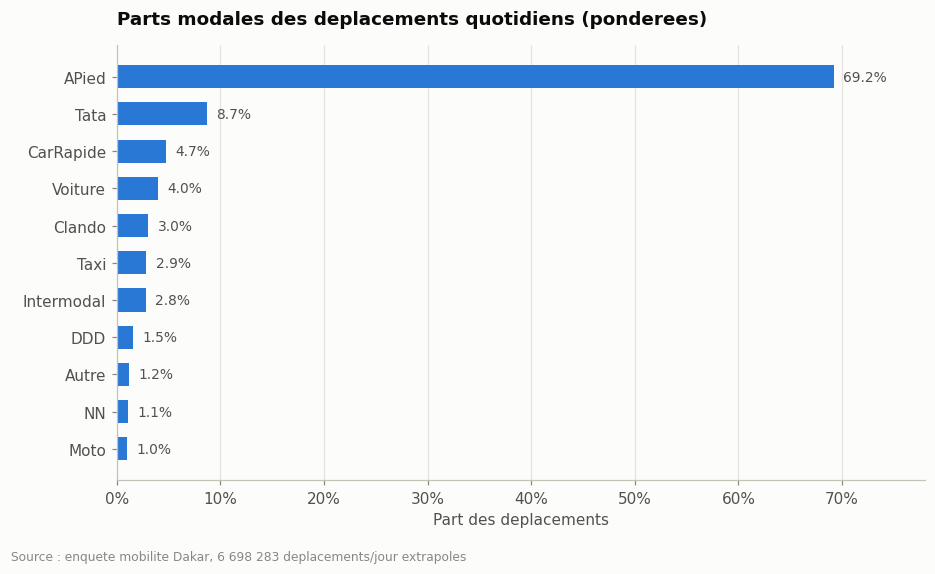

In [ ]:
p = parts.sort_values("part_pct")

fig, ax = plt.subplots(figsize=(8.5, 5))
barres = ax.barh(p.moyen_transport, p.part_pct, height=0.62, color=SERIE_1)

# Label direct en bout de barre : la valeur reste lisible sans survol
for barre, valeur in zip(barres, p.part_pct):
    ax.text(valeur + 0.9, barre.get_y() + barre.get_height() / 2,
            f"{valeur:.1f}%", va="center", ha="left", color=ENCRE_2, fontsize=9)

ax.set_xlim(0, 78)
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
habiller(ax, "Parts modales des deplacements quotidiens (ponderees)",
         x="Part des deplacements", grille="x")
fig.text(0.005, -0.03, "Source : enquete mobilite Dakar, 6 698 283 deplacements/jour extrapoles",
         fontsize=8, color=MUET)
plt.tight_layout()
plt.show()

Les parts pondérées permettent de comparer la marche, les transports collectifs et les modes individuels. Les coûts moyens doivent être interprétés avec les effectifs disponibles par mode.


## 3. Motifs de déplacement

Les motifs sont présentés avec les retours au domicile, puis hors retours.


In [ ]:
motifs_bruts = agreger(propres, ["motif"], TOTAL_PONDERE).limit(12).toPandas()

# Hors retour au domicile : les motifs reellement generateurs
hors_retour = propres.filter(~F.col("est_retour_domicile"))
TOTAL_HORS_RETOUR = hors_retour.agg(F.sum("poids_extra")).collect()[0][0]
motifs_generateurs = agreger(hors_retour, ["motif"], TOTAL_HORS_RETOUR).limit(12).toPandas()

print(f"Retours au domicile : {100 * (TOTAL_PONDERE - TOTAL_HORS_RETOUR) / TOTAL_PONDERE:.1f}% "
      f"du total")
motifs_generateurs.head(8)

Retours au domicile : 43.1% du total


,motif,nb_enquetes,deplacements,part_pct
0,TravailHabituel,5309,816779.075657,21.41
1,AchatsAlimentaires,4285,596940.980059,15.65
2,Etudes,3939,569546.393819,14.93
3,VisiteAmis,1941,285288.988595,7.48
4,AutreMotifTravail,1423,220302.259368,5.77
5,SportsLoisirs,1180,173009.117550,4.54
6,AchatsNonAlimentaires,1029,151755.523422,3.98
7,VisiteFamille,1018,145639.835638,3.82


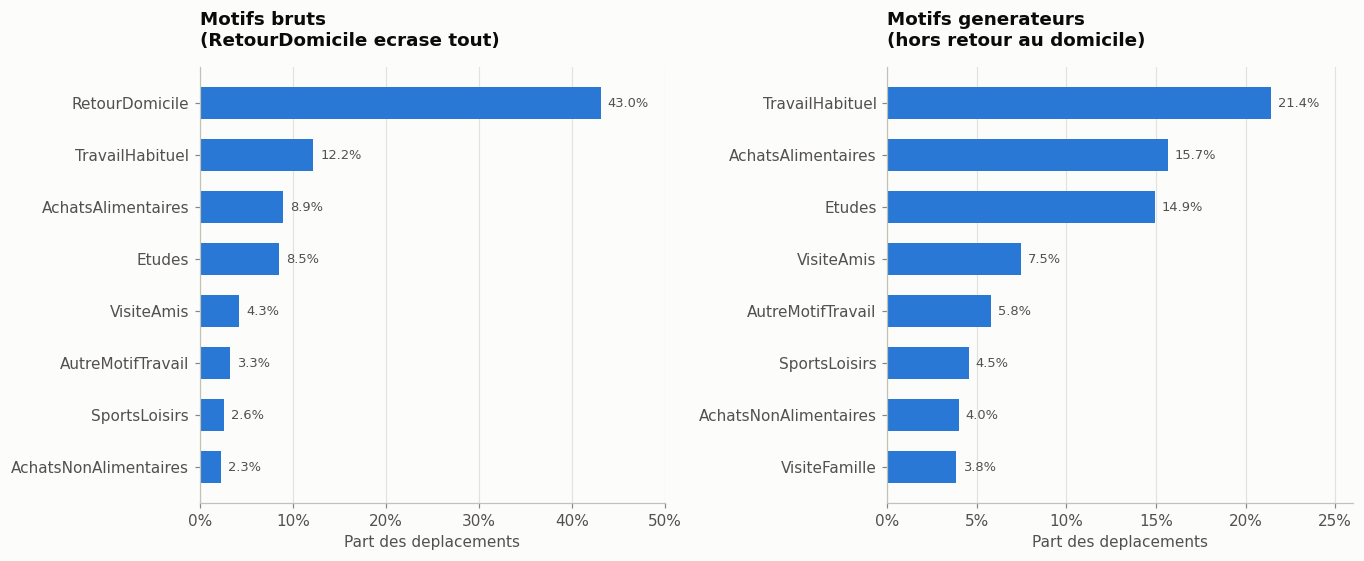

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.2))

for ax, donnees, titre, borne in [
    (axes[0], motifs_bruts.head(8), "Motifs bruts\n(RetourDomicile ecrase tout)", 50),
    (axes[1], motifs_generateurs.head(8), "Motifs generateurs\n(hors retour au domicile)", 26),
]:
    d = donnees.sort_values("part_pct")
    barres = ax.barh(d.motif, d.part_pct, height=0.62, color=SERIE_1)
    for barre, valeur in zip(barres, d.part_pct):
        ax.text(valeur + borne * 0.015, barre.get_y() + barre.get_height() / 2,
                f"{valeur:.1f}%", va="center", color=ENCRE_2, fontsize=8.5)
    ax.set_xlim(0, borne)
    ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
    habiller(ax, titre, x="Part des deplacements", grille="x")

plt.tight_layout()
plt.show()

La comparaison hors `RetourDomicile` décrit la répartition des autres motifs. Les pourcentages utilisent alors un dénominateur différent de celui de la distribution complète.


## 4. Distribution des durées


In [ ]:
duree_pd = propres.select("duree_mn", "poids_extra").toPandas()

classes = agreger(propres, ["classe_duree"], TOTAL_PONDERE).toPandas()
quantiles = propres.approxQuantile("duree_mn", [0.25, 0.5, 0.75, 0.9, 0.99], 0.001)
print("Quartiles de duree (mn) — Q1/mediane/Q3/p90/p99 :", [round(q) for q in quantiles])
classes.sort_values("part_pct", ascending=False)

Quartiles de duree (mn) — Q1/mediane/Q3/p90/p99 : [5, 10, 22, 45, 115]


,classe_duree,nb_enquetes,deplacements,part_pct
0,<=10 mn,24686,3.548537e+06,52.97
1,11-20 mn,9445,1.396033e+06,20.84
2,21-40 mn,6837,1.032496e+06,15.41
3,41-60 mn,2823,4.418479e+05,6.60
4,>60 mn,1811,2.799277e+05,4.18


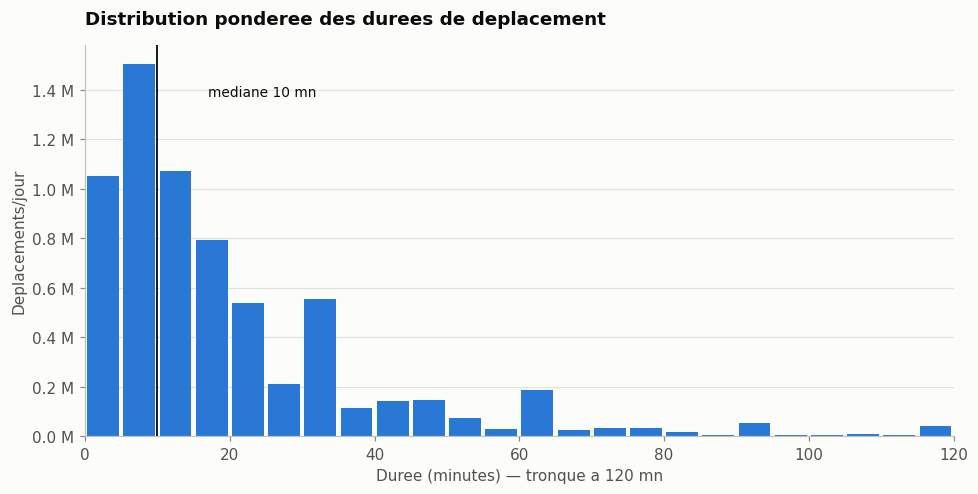

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4.6))

ax.hist(duree_pd.duree_mn, bins=range(0, 125, 5), weights=duree_pd.poids_extra,
        color=SERIE_1, rwidth=0.88)   # ponderation : poids_extra en poids d'histogramme

mediane = quantiles[1]
ax.axvline(mediane, color=ENCRE, linewidth=1.2, zorder=5)
ax.annotate(f"mediane {mediane:.0f} mn", xy=(mediane, ax.get_ylim()[1] * 0.88),
            xytext=(mediane + 7, ax.get_ylim()[1] * 0.88),
            color=ENCRE, fontsize=9, va="center")

ax.set_xlim(0, 120)
ax.yaxis.set_major_formatter(lambda v, _: f"{v / 1e6:.1f} M")
habiller(ax, "Distribution ponderee des durees de deplacement",
         x="Duree (minutes) — tronque a 120 mn", y="Deplacements/jour")
plt.tight_layout()
plt.show()

La médiane, les quantiles et la moyenne décrivent des aspects complémentaires de la distribution. Les valeurs extrêmes doivent être examinées avec les indicateurs de qualité.


## 5. Profil horaire des déplacements


In [ ]:
profil = (
    propres
    .withColumn("heure", ((F.col("heure_depart_minutes") % 1440) / 60).cast("int"))
    .groupBy("heure")
    .agg(F.sum("poids_extra").alias("deplacements"))
    .withColumn("part_pct", F.round(100 * F.col("deplacements") / TOTAL_PONDERE, 2))
    .orderBy("heure").toPandas()
)
profil.set_index("heure").T

heure,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
deplacements,21946.205492,9756.828729,4577.003666,6441.893117,6091.948146,44446.730312,125156.405517,621038.832749,374282.729149,455012.454637,529666.769328,339119.532496,386647.599883,385111.973216,392609.765532,268605.986898,319869.776437,561438.600765,511176.849997,492075.294162,356717.655442,247649.624374,151870.243243,87530.841053
part_pct,0.330000,0.150000,0.070000,0.100000,0.090000,0.660000,1.870000,9.270000,5.590000,6.790000,7.910000,5.060000,5.770000,5.750000,5.860000,4.010000,4.780000,8.380000,7.630000,7.350000,5.330000,3.700000,2.270000,1.310000


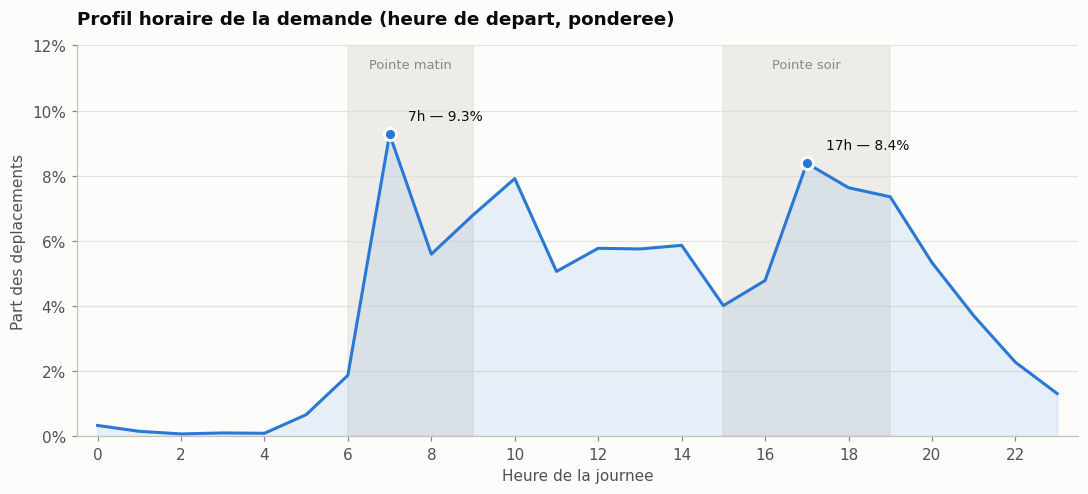

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4.6))

# Bandes de pointe en fond : contexte, sans concurrencer la courbe
for debut, fin, etiquette in [(6, 9, "Pointe matin"), (15, 19, "Pointe soir")]:
    ax.axvspan(debut, fin, color=GRILLE, alpha=0.55, zorder=0)
    ax.text((debut + fin) / 2, 11.3, etiquette, ha="center", fontsize=8.5, color=MUET)

ax.plot(profil.heure, profil.part_pct, color=SERIE_1, linewidth=2, zorder=3)
ax.fill_between(profil.heure, profil.part_pct, color=SERIE_1, alpha=0.1, zorder=2)

# Labels directs sur les deux extremes seulement
for heure in [7, 17]:
    valeur = profil.loc[profil.heure == heure, "part_pct"].iloc[0]
    ax.plot(heure, valeur, "o", color=SERIE_1, markersize=8,
            markeredgecolor=SURFACE, markeredgewidth=2, zorder=4)
    ax.annotate(f"{heure}h — {valeur:.1f}%", xy=(heure, valeur), xytext=(heure + 0.45, valeur + 0.45),
                color=ENCRE, fontsize=9)

ax.set_xticks(range(0, 24, 2))
ax.set_xlim(-0.5, 23.5)
ax.set_ylim(0, 12)
ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
habiller(ax, "Profil horaire de la demande (heure de depart, ponderee)",
         x="Heure de la journee", y="Part des deplacements")
plt.tight_layout()
plt.show()

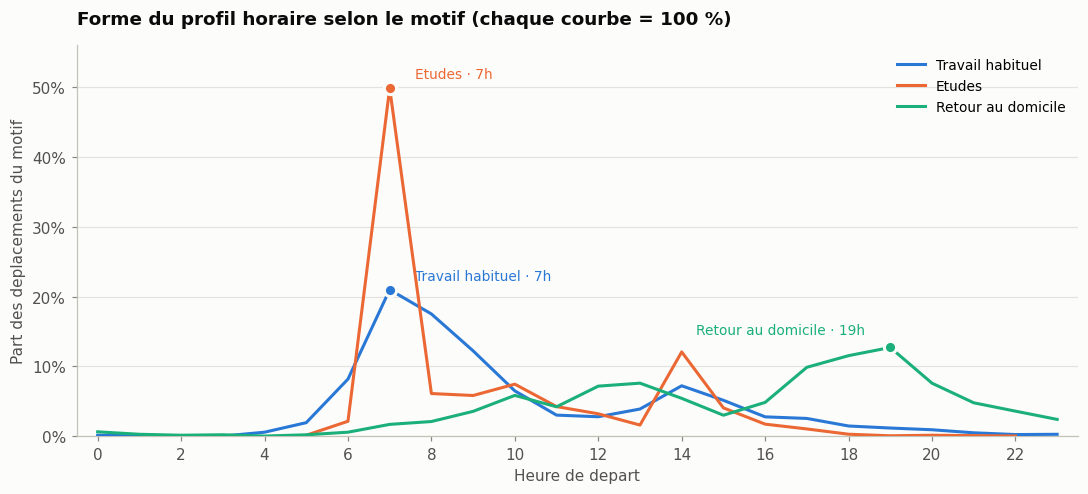

In [ ]:
grands_motifs = ["TravailHabituel", "Etudes", "RetourDomicile"]
libelles = {"TravailHabituel": "Travail habituel", "Etudes": "Etudes",
            "RetourDomicile": "Retour au domicile"}

profils = (
    propres.filter(F.col("motif").isin(grands_motifs))
    .withColumn("heure", ((F.col("heure_depart_minutes") % 1440) / 60).cast("int"))
    .groupBy("motif", "heure").agg(F.sum("poids_extra").alias("deplacements"))
    .toPandas()
)
# Chaque courbe est normalisee a 100 % d'elle-meme : on compare des FORMES
profils["part_motif"] = profils.groupby("motif").deplacements.transform(lambda s: 100 * s / s.sum())

fig, ax = plt.subplots(figsize=(10, 4.6))

# Decalage du label de chaque pic, choisi pour qu'aucun ne chevauche une courbe
DECALAGES = {"TravailHabituel": (0.6, 1.4, "left"),
             "Etudes": (0.6, 1.4, "left"),
             "RetourDomicile": (-0.6, 2.0, "right")}

for motif, couleur in zip(grands_motifs, [SERIE_1, SERIE_2, SERIE_3]):
    d = profils[profils.motif == motif].sort_values("heure")
    ax.plot(d.heure, d.part_motif, color=couleur, linewidth=2,
            label=libelles[motif], zorder=3)
    # Label direct au pic de chaque courbe (3 series -> toutes labellisees)
    pic = d.loc[d.part_motif.idxmax()]
    ax.plot(pic.heure, pic.part_motif, "o", color=couleur, markersize=8,
            markeredgecolor=SURFACE, markeredgewidth=2, zorder=4)
    dx, dy, align = DECALAGES[motif]
    ax.annotate(f"{libelles[motif]} · {pic.heure:.0f}h", xy=(pic.heure, pic.part_motif),
                xytext=(pic.heure + dx, pic.part_motif + dy),
                color=couleur, fontsize=9, ha=align)

ax.set_xticks(range(0, 24, 2))
ax.set_xlim(-0.5, 23.5)
ax.set_ylim(0, 56)
ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.legend(loc="upper right", ncol=1)
habiller(ax, "Forme du profil horaire selon le motif (chaque courbe = 100 %)",
         x="Heure de depart", y="Part des deplacements du motif")
plt.tight_layout()
plt.show()

## 6. Mobilité selon le jour observé


In [ ]:
jours = (
    individus.groupBy("jour_enquete")
    .agg(F.count("*").alias("individus_enquetes"),
         F.round(F.sum("poids"), 0).alias("individus_ponderes"),
         F.round(100 * F.sum(F.col("nb_deplacements") * F.col("poids")) / TOTAL_PONDERE, 2)
          .alias("part_deplacements_pct"),
         F.round(F.sum(F.col("nb_deplacements") * F.col("poids")) / F.sum("poids"), 2)
          .alias("mobilite_par_personne"))
    .toPandas()
)

ordre = ["Mardi", "Mercredi", "Jeudi", "Vendredi", "Samedi", "Dimanche"]
jours = jours.set_index("jour_enquete").reindex([j for j in ordre if j in set(jours.jour_enquete)])
jours

,individus_enquetes,individus_ponderes,part_deplacements_pct,mobilite_par_personne
jour_enquete,,,,
Mardi,1792,268453.0,16.22,4.05
Mercredi,2213,338799.0,20.31,4.02
Jeudi,1928,272658.0,15.82,3.89
Vendredi,1562,247444.0,14.34,3.88
Samedi,1646,236214.0,13.67,3.88
Dimanche,2316,339711.0,19.63,3.87


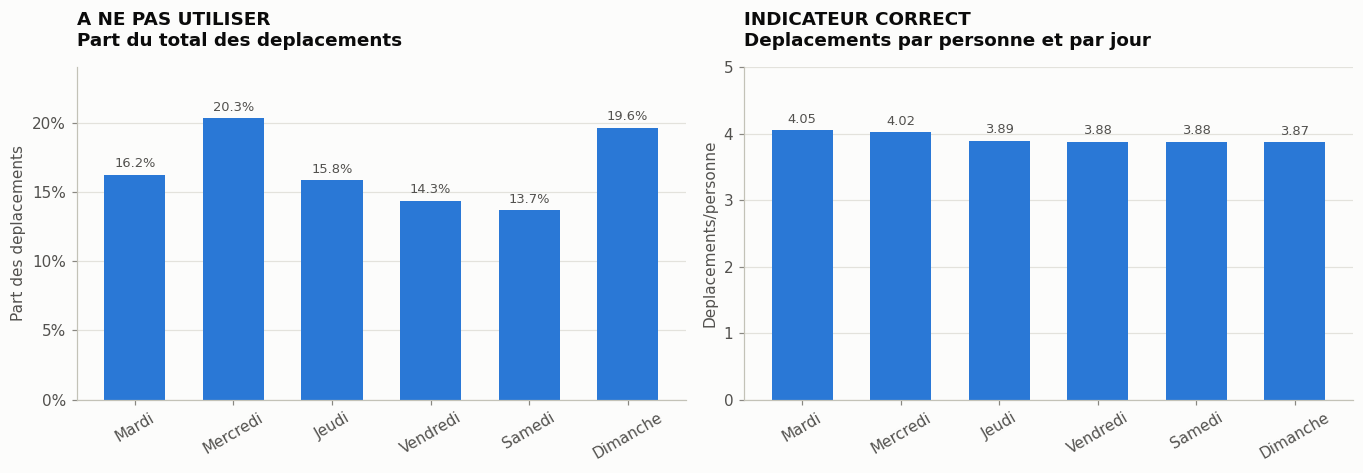

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))

# Panneau 1 : l'indicateur TROMPEUR
b1 = axes[0].bar(jours.index, jours.part_deplacements_pct, width=0.62, color=SERIE_1)
axes[0].bar_label(b1, fmt="%.1f%%", padding=3, color=ENCRE_2, fontsize=8.5)
axes[0].set_ylim(0, 24)
axes[0].yaxis.set_major_formatter(PercentFormatter(decimals=0))
habiller(axes[0], "A NE PAS UTILISER\nPart du total des deplacements",
         y="Part des deplacements")

# Panneau 2 : l'indicateur JUSTE
b2 = axes[1].bar(jours.index, jours.mobilite_par_personne, width=0.62, color=SERIE_1)
axes[1].bar_label(b2, fmt="%.2f", padding=3, color=ENCRE_2, fontsize=8.5)
axes[1].set_ylim(0, 5)
habiller(axes[1], "INDICATEUR CORRECT\nDeplacements par personne et par jour",
         y="Deplacements/personne")

for ax in axes:
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

## 7. âge, sexe et accès aux modes

Les distributions démographiques sont calculées sur les individus. Les indicateurs de mobilité sont calcul's sur les déplacements.


In [ ]:
# Demonstration du melange effectif / mobilite
pyr_fausse = (propres.groupBy("tranche_age").pivot("sexe").agg(F.sum("poids_extra"))
                     .orderBy("tranche_age").toPandas().set_index("tranche_age"))
pyr_juste = (individus.groupBy("tranche_age").pivot("sexe").agg(F.sum("poids"))
                      .orderBy("tranche_age").toPandas().set_index("tranche_age"))

comparaison = pd.DataFrame({
    "ratio H/F sur les DEPLACEMENTS": (pyr_fausse.Homme / pyr_fausse.Femme).round(2),
    "ratio H/F sur les INDIVIDUS": (pyr_juste.Homme / pyr_juste.Femme).round(2),
})
comparaison

,ratio H/F sur les DEPLACEMENTS,ratio H/F sur les INDIVIDUS
tranche_age,,
00-14,0.95,0.88
15-24,0.98,0.87
25-34,1.00,0.90
35-49,1.10,0.97
50-64,1.27,1.12
65+,3.07,2.18


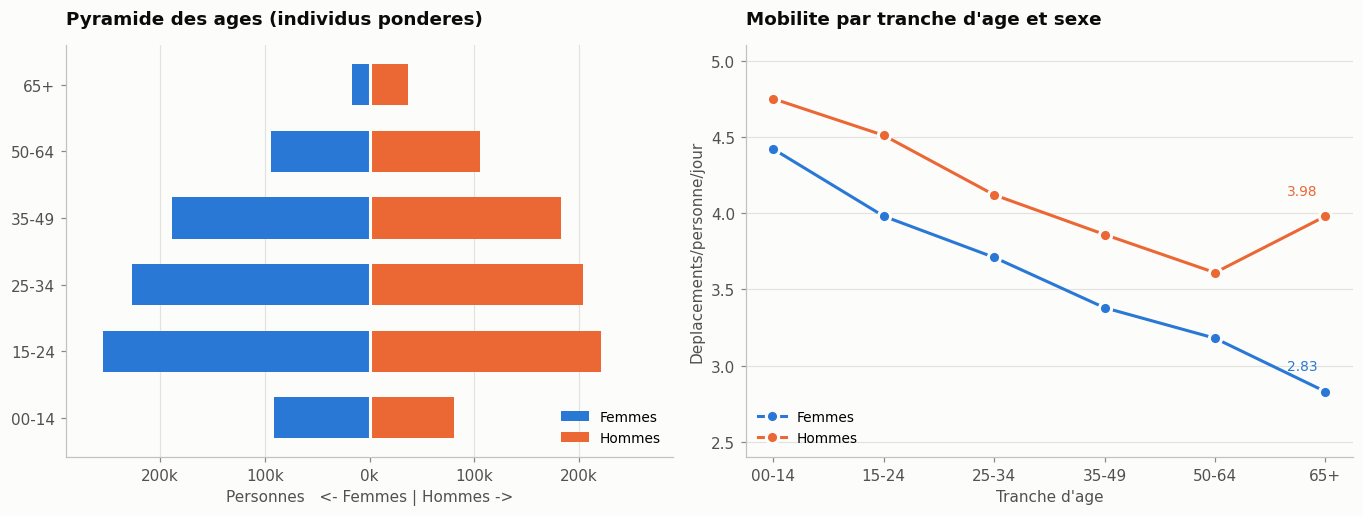

In [ ]:
mobilite = (
    individus.groupBy("tranche_age").pivot("sexe")
    .agg(F.round(F.sum(F.col("nb_deplacements") * F.col("poids")) / F.sum("poids"), 2))
    .orderBy("tranche_age").toPandas().set_index("tranche_age")
)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))

# --- Pyramide des ages (individus ponderes) ---------------------------------
y = list(range(len(pyr_juste)))
# Les deux sexes partagent la meme ligne : c'est ce qui en fait une pyramide
axes[0].barh(y, -pyr_juste.Femme / 1000, height=0.62, color=SERIE_1, label="Femmes")
axes[0].barh(y, pyr_juste.Homme / 1000, height=0.62, color=SERIE_2, label="Hommes")
axes[0].set_yticks(y, pyr_juste.index)
axes[0].axvline(0, color=SURFACE, linewidth=2, zorder=4)   # separation de 2px
axes[0].xaxis.set_major_formatter(lambda v, _: f"{abs(v):.0f}k")
axes[0].set_xlim(-290, 290)
axes[0].legend(loc="lower right")
habiller(axes[0], "Pyramide des ages (individus ponderes)",
         x="Personnes   <- Femmes | Hommes ->", grille="x")

# --- Mobilite par tranche et sexe -------------------------------------------
axes[1].plot(mobilite.index, mobilite.Femme, color=SERIE_1, linewidth=2,
             marker="o", markersize=8, markeredgecolor=SURFACE, markeredgewidth=2,
             label="Femmes")
axes[1].plot(mobilite.index, mobilite.Homme, color=SERIE_2, linewidth=2,
             marker="o", markersize=8, markeredgecolor=SURFACE, markeredgewidth=2,
             label="Hommes")
for sexe, couleur in [("Femme", SERIE_1), ("Homme", SERIE_2)]:
    axes[1].annotate(f"{mobilite[sexe].iloc[-1]:.2f}",
                     xy=(len(mobilite) - 1, mobilite[sexe].iloc[-1]),
                     xytext=(len(mobilite) - 1.35, mobilite[sexe].iloc[-1] + 0.14),
                     color=couleur, fontsize=9)
axes[1].set_ylim(2.4, 5.1)
axes[1].legend(loc="lower left")
habiller(axes[1], "Mobilite par tranche d'age et sexe",
         x="Tranche d'age", y="Deplacements/personne/jour")

plt.tight_layout()
plt.show()

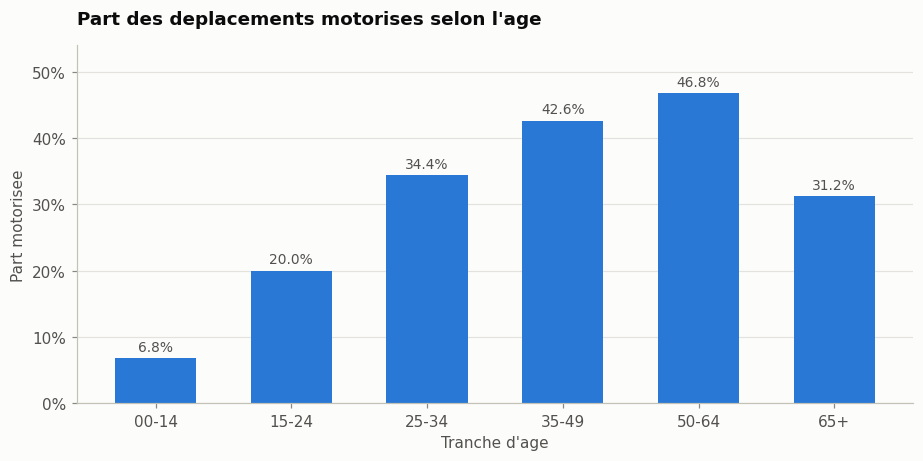

,tranche_age,part_motorisee_pct,part_multimodale_pct
0,00-14,6.8,4.3
1,15-24,20.0,13.6
2,25-34,34.4,21.3
3,35-49,42.6,23.4
4,50-64,46.8,24.6
5,65+,31.2,16.9


In [ ]:
acces = (
    propres.groupBy("tranche_age")
    .agg(F.round(100 * F.sum(F.when(F.col("est_motorise"), F.col("poids_extra"))
                              .otherwise(0)) / F.sum("poids_extra"), 1).alias("part_motorisee_pct"),
         F.round(100 * F.sum(F.when(F.col("est_multimodal"), F.col("poids_extra"))
                              .otherwise(0)) / F.sum("poids_extra"), 1).alias("part_multimodale_pct"))
    .orderBy("tranche_age").toPandas()
)

fig, ax = plt.subplots(figsize=(8.5, 4.3))
barres = ax.bar(acces.tranche_age, acces.part_motorisee_pct, width=0.6, color=SERIE_1)
ax.bar_label(barres, fmt="%.1f%%", padding=3, color=ENCRE_2, fontsize=9)
ax.set_ylim(0, 54)
ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
habiller(ax, "Part des deplacements motorises selon l'age",
         x="Tranche d'age", y="Part motorisee")
plt.tight_layout()
plt.show()
acces

## 8. Répartition spatiale des flux

La matrice origine-destination est agrégée par département.


In [ ]:
print("Deplacements internes a la strate      : %.1f%%" % (
    100 * propres.filter(F.col("deplacement_intra_strate")).agg(F.sum("poids_extra")).collect()[0][0]
    / TOTAL_PONDERE))
print("Deplacements internes au departement   : %.1f%%" % (
    100 * propres.filter(F.col("deplacement_intra_departement"))
                 .agg(F.sum("poids_extra")).collect()[0][0] / TOTAL_PONDERE))

od_dep = (
    propres.filter(F.col("departement_depart").isNotNull() &
                   F.col("departement_arrivee").isNotNull())
    .groupBy("departement_depart").pivot("departement_arrivee")
    .agg(F.round(100 * F.sum("poids_extra") / TOTAL_PONDERE, 2))
    .orderBy("departement_depart").toPandas().set_index("departement_depart")
)
od_dep = od_dep.reindex(index=["DAKAR", "GUEDIAWAYE", "PIKINE", "RUFISQUE"],
                        columns=["DAKAR", "GUEDIAWAYE", "PIKINE", "RUFISQUE"])
od_dep

Deplacements internes a la strate      : 68.2%
Deplacements internes au departement   : 89.4%


,DAKAR,GUEDIAWAYE,PIKINE,RUFISQUE
departement_depart,,,,
DAKAR,37.05,0.97,2.11,0.38
GUEDIAWAYE,0.97,7.43,0.87,0.07
PIKINE,2.06,0.89,30.32,0.44
RUFISQUE,0.38,0.07,0.41,14.61


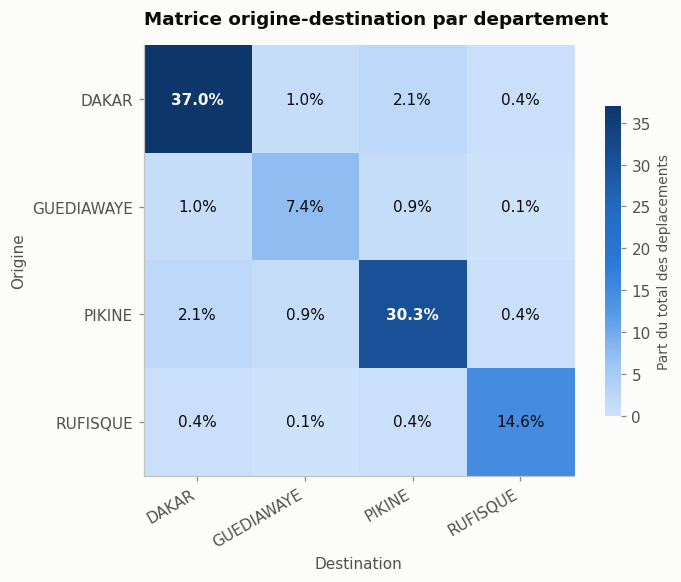

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5.4))

# Rampe sequentielle a UNE teinte : la magnitude est une grandeur ordonnee
image = ax.imshow(od_dep.values, cmap=RAMPE_BLEUE, vmin=0, vmax=od_dep.values.max())

ax.set_xticks(range(len(od_dep.columns)), od_dep.columns, rotation=30, ha="right")
ax.set_yticks(range(len(od_dep.index)), od_dep.index)

# Chaque cellule porte sa valeur : la couleur n'est jamais le seul encodage
seuil = od_dep.values.max() * 0.55
for i in range(od_dep.shape[0]):
    for j in range(od_dep.shape[1]):
        valeur = od_dep.values[i, j]
        ax.text(j, i, f"{valeur:.1f}%", ha="center", va="center", fontsize=10,
                color=SURFACE if valeur > seuil else ENCRE,
                fontweight="semibold" if valeur > seuil else "normal")

barre = fig.colorbar(image, ax=ax, shrink=0.72)
barre.set_label("Part du total des deplacements", color=ENCRE_2, fontsize=9)
barre.outline.set_visible(False)

ax.set_title("Matrice origine-destination par departement", loc="left", pad=14)
ax.set_xlabel("Destination", color=ENCRE_2)
ax.set_ylabel("Origine", color=ENCRE_2)
ax.grid(False)
plt.tight_layout()
plt.show()

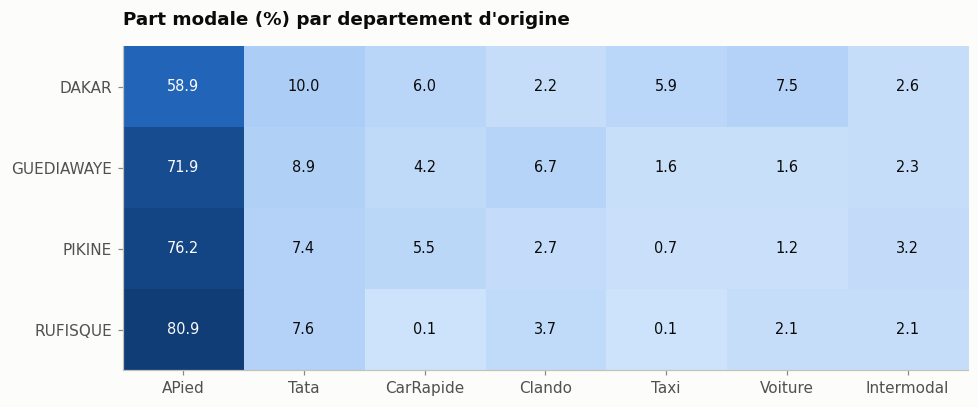

,APied,Tata,CarRapide,Clando,Taxi,Voiture,Intermodal
departement_depart,,,,,,,
DAKAR,58.9,10.0,6.0,2.2,5.9,7.5,2.6
GUEDIAWAYE,71.9,8.9,4.2,6.7,1.6,1.6,2.3
PIKINE,76.2,7.4,5.5,2.7,0.7,1.2,3.2
RUFISQUE,80.9,7.6,0.1,3.7,0.1,2.1,2.1


In [ ]:
modal_dep = (
    propres.filter(F.col("departement_depart").isNotNull())
    .groupBy("departement_depart").pivot("moyen_transport").agg(F.sum("poids_extra"))
    .orderBy("departement_depart").toPandas().set_index("departement_depart")
)
modal_dep = (100 * modal_dep.div(modal_dep.sum(axis=1), axis=0)).round(1)
modal_dep = modal_dep.reindex(index=["DAKAR", "GUEDIAWAYE", "PIKINE", "RUFISQUE"])[
    ["APied", "Tata", "CarRapide", "Clando", "Taxi", "Voiture", "Intermodal"]]

fig, ax = plt.subplots(figsize=(9, 3.8))
image = ax.imshow(modal_dep.values, cmap=RAMPE_BLEUE, vmin=0, vmax=85, aspect="auto")

ax.set_xticks(range(len(modal_dep.columns)), modal_dep.columns)
ax.set_yticks(range(len(modal_dep.index)), modal_dep.index)
for i in range(modal_dep.shape[0]):
    for j in range(modal_dep.shape[1]):
        valeur = modal_dep.values[i, j]
        ax.text(j, i, f"{valeur:.1f}", ha="center", va="center", fontsize=9.5,
                color=SURFACE if valeur > 46 else ENCRE)

ax.set_title("Part modale (%) par departement d'origine", loc="left", pad=14)
ax.grid(False)
plt.tight_layout()
plt.show()
modal_dep

## 9. Durée, coût et intermodalité

Analyse des relations entre les variables quantitatives.


In [ ]:
correlations = propres.select(
    F.round(F.corr("duree_mn", "cout_nettoye"), 3).alias("duree~cout"),
    F.round(F.corr("duree_mn", "nb_trajets"), 3).alias("duree~nb_trajets"),
    F.round(F.corr("cout_nettoye", "nb_trajets"), 3).alias("cout~nb_trajets"),
    F.round(F.corr("age", "duree_mn"), 3).alias("age~duree"),
).toPandas().T.rename(columns={0: "correlation"})
correlations

,correlation
duree~cout,0.394
duree~nb_trajets,0.433
cout~nb_trajets,0.244
age~duree,0.130


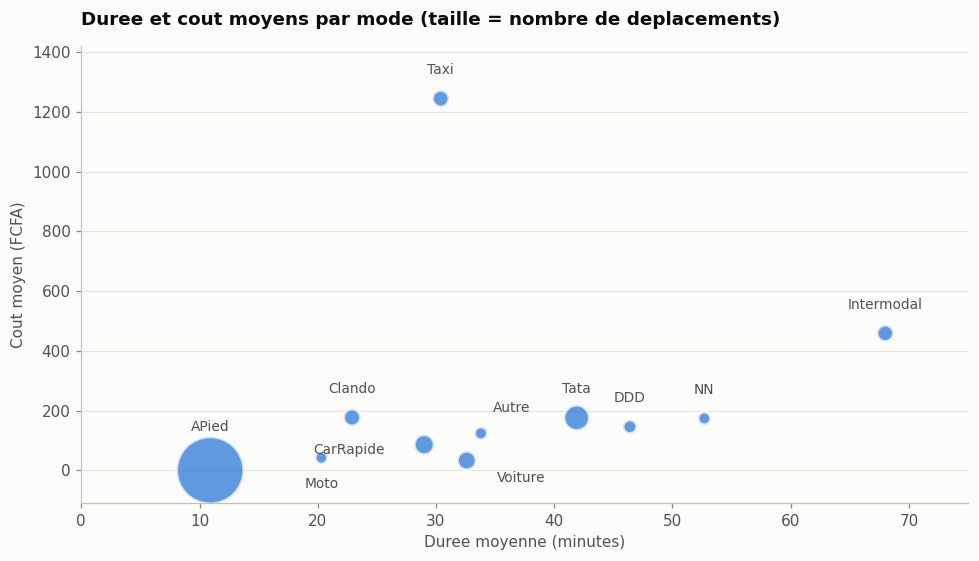

,moyen_transport,duree_moy,cout_moy,volume
0,APied,10.9,0.0,4.635208e+06
8,Tata,41.9,176.0,5.801144e+05
7,CarRapide,29.0,86.0,3.176694e+05
1,Voiture,32.6,33.0,2.669045e+05
6,Clando,22.9,177.0,2.039982e+05
4,Taxi,30.4,1245.0,1.910209e+05
5,Intermodal,68.0,459.0,1.864703e+05
9,DDD,46.4,146.0,1.018289e+05
2,Autre,33.8,124.0,7.777378e+04
10,NN,52.7,174.0,7.186615e+04


In [ ]:
nuage = (
    propres.groupBy("moyen_transport")
    .agg(F.round(F.sum("duree_ponderee") / F.sum("poids_extra"), 1).alias("duree_moy"),
         F.round(F.sum("cout_pondere") / F.sum("poids_extra"), 0).alias("cout_moy"),
         F.sum("poids_extra").alias("volume"))
    .toPandas()
)

fig, ax = plt.subplots(figsize=(9, 5.2))

# Une seule serie -> une seule couleur (slot 1). La taille encode le volume.
ax.scatter(nuage.duree_moy, nuage.cout_moy,
           s=40 + 1900 * nuage.volume / nuage.volume.max(),
           color=SERIE_1, alpha=0.75, edgecolor=SURFACE, linewidth=2, zorder=3)

# Decalages manuels la ou les points se serrent (CarRapide / Autre / Voiture)
DECALAGES_MODE = {"CarRapide": (-26, -6, "right"), "Autre": (8, 14, "left"),
                  "Voiture": (20, -14, "left"), "APied": (0, 26, "center"),
                  "Moto": (0, -20, "center")}

for _, ligne in nuage.iterrows():
    dx, dy, align = DECALAGES_MODE.get(ligne.moyen_transport, (0, 16, "center"))
    ax.annotate(ligne.moyen_transport, xy=(ligne.duree_moy, ligne.cout_moy),
                xytext=(dx, dy), textcoords="offset points",
                ha=align, fontsize=9, color=ENCRE_2)

ax.set_ylim(-110, 1420)
ax.set_xlim(0, 75)
habiller(ax, "Duree et cout moyens par mode (taille = nombre de deplacements)",
         x="Duree moyenne (minutes)", y="Cout moyen (FCFA)")
plt.tight_layout()
plt.show()
nuage.sort_values("volume", ascending=False)

## Synthèse et limites

Les indicateurs doivent être recalculés après modification des règles de nettoyage.

La base ne renseigne pas les distances, les revenus ni la motorisation du ménage. Chaque individu est observé sur un seul jour. Le code zex regroupe les zones extérieures.


## Vérifications méthodologiques avant modélisation

Ces contrôles permettent de distinguer les règles documentées des hypothèses de nettoyage. Les valeurs et les taux doivent être recalculés après chaque modification du notebook.


In [ ]:
print("Bilan actualisé :", "source", N_BRUT, "valides", propres.count(), "rejets", rejets.count())
print("Durées atypiques (>10h) conservées :", propres.filter(F.col("duree_atypique")).count())
print("Motifs des rejets :")
rejets.groupBy("motif_rejet").count().orderBy(F.desc("count")).show(truncate=False)
print("Codes de strates conservés :")
for col in ["strate_depart", "strate_arrivee"]:
    propres.groupBy(col).count().orderBy(F.desc("count")).show(12, truncate=False)


Bilan actualisé : source 45605 valides 45602 rejets 3
Durées atypiques (>10h) conservées : 5
Motifs des rejets :
+-------------------+-----+
|motif_rejet        |count|
+-------------------+-----+
|heure_hhmm_invalide|3    |
+-------------------+-----+

Codes de strates conservés :
+-------------+-----+
|strate_depart|count|
+-------------+-----+
|P09          |2505 |
|P08          |1846 |
|D16          |1800 |
|R04          |1764 |
|P06          |1631 |
|D06          |1602 |
|P02          |1570 |
|P04          |1559 |
|R03          |1459 |
|R05          |1378 |
|R07          |1331 |
|D08          |1209 |
+-------------+-----+
only showing top 12 rows

+--------------+-----+
|strate_arrivee|count|
+--------------+-----+
|P09           |2505 |
|P08           |1849 |
|D16           |1804 |
|R04           |1763 |
|P06           |1631 |
|D06           |1591 |
|P02           |1572 |
|P04           |1557 |
|R03           |1461 |
|R05           |1382 |
|R07           |1333 |
|D08           |1

# Partie III - Prédiction du motif de déplacement

La cible `motif_cle` est prédite à partir des caractéristiques des déplacements et des individus.


**Méthode :** la cible `motif_cle` est une variable catégorielle. Le pipeline encode les variables explicatives, apprend sur 80 % des observations et évalue sur 20 %. Les valeurs nulles des variables numériques sont imputées à partir du jeu d'entraînement. Le modèle est comparé à une baseline qui prédit toujours la classe majoritaire. Les performances par classe sont calculées dans Spark, sans `toPandas()` et sans graphiques. Les sorties doivent être recalculées après les modifications du nettoyage.


In [ ]:
# Les imports Spark et ML déjà effectués restent disponibles dans la session.
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, Imputer
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

# Utiliser la base propre en mémoire (évite une relecture inutile du Parquet).
df_model = propres.filter(F.col("motif_cle").isNotNull())
print("Observations disponibles pour la modélisation :", df_model.count())


Observations disponibles pour la modélisation : 45602


In [ ]:

# Variables explicatives
categorical_cols = [
    "sexe",
    "tranche_age",
    "periode_journee",
    "moyen_transport",
    "departement_depart",
    "departement_arrivee"
]

numeric_cols = [
    "duree_mn",
    "age",
    "nb_trajets"
]

# Conserver les motifs renseignés
df_model = df_model.filter(
    F.col("motif_cle").isNotNull()
)

# Remplacer les catégories manquantes par une modalité explicite
df_model = df_model.fillna(
    "Non_renseigne",
    subset=categorical_cols
)

# Vérifier les effectifs
print("Observations :", df_model.count())
print("Motifs distincts :", df_model.select("motif_cle").distinct().count())

# Séparation entraînement / test
train_df, test_df = df_model.randomSplit(
    [0.8, 0.2],
    seed=42
)

print("Train :", train_df.count())
print("Test :", test_df.count())



Observations : 45602
Motifs distincts : 24
Train : 36655
Test : 8947


In [ ]:

# Encodage des variables catégorielles
indexers = [
    StringIndexer(
        inputCol=c,
        outputCol=f"{c}_indexed",
        handleInvalid="keep"
    )
    for c in categorical_cols
]

encoders = [
    OneHotEncoder(
        inputCol=f"{c}_indexed",
        outputCol=f"{c}_encoded",
        handleInvalid="keep"
    )
    for c in categorical_cols
]

# Imputation numérique
from pyspark.ml.feature import Imputer

imputer = Imputer(
    inputCols=numeric_cols,
    outputCols=[f"{c}_imputed" for c in numeric_cols],
    strategy="median"
)

# Variable cible
label_indexer = StringIndexer(
    inputCol="motif_cle",
    outputCol="label",
    handleInvalid="skip"
)

# Assemblage des variables
assembler = VectorAssembler(
    inputCols=(
        [f"{c}_encoded" for c in categorical_cols]
        + [f"{c}_imputed" for c in numeric_cols]
    ),
    outputCol="features",
    handleInvalid="error"
)

# Random Forest
rf = RandomForestClassifier(
    labelCol="label",
    featuresCol="features",
    numTrees=100,
    maxDepth=8,
    seed=42
)

pipeline = Pipeline(
    stages=indexers + encoders +
    [imputer, label_indexer, assembler, rf]
)

print("Pipeline construit avec succès.")


Pipeline construit avec succès.


In [ ]:

print("Début de l'entraînement...")

model = pipeline.fit(train_df)

print("Random Forest entraîné avec succès.")


Début de l'entraînement...
Random Forest entraîné avec succès.


In [ ]:

# Prédictions sur le jeu de test
predictions = model.transform(test_df)

# Récupérer les noms des motifs
label_stage = model.stages[
    len(indexers) + len(encoders) + 1
]

class_names = list(label_stage.labels)

print("Nombre de classes apprises :", len(class_names))

# Vérifier le nombre de prédictions évaluables
n_test = test_df.count()
n_pred = predictions.count()

print("Observations test :", n_test)
print("Observations évaluées :", n_pred)
print("Observations exclues :", n_test - n_pred)

# Évaluation
evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction"
)

metrics = [
    "accuracy",
    "f1",
    "weightedPrecision",
    "weightedRecall"
]

print("\nPERFORMANCES RANDOM FOREST")

for metric in metrics:
    score = evaluator.setMetricName(metric).evaluate(predictions)
    print(f"{metric} : {score:.4f}")


Nombre de classes apprises : 24
Observations test : 8947
Observations évaluées : 8947
Observations exclues : 0

PERFORMANCES RANDOM FOREST
accuracy : 0.5194
f1 : 0.3966
weightedPrecision : 0.3423
weightedRecall : 0.5194


In [ ]:

# Classe majoritaire dans le train
majority_label = (
    model.transform(train_df)
    .groupBy("label")
    .count()
    .orderBy(F.desc("count"))
    .first()["label"]
)

# Baseline sur les observations test évaluables
baseline_accuracy = (
    predictions
    .filter(F.col("label") == majority_label)
    .count() / predictions.count()
)

rf_accuracy = evaluator.setMetricName(
    "accuracy"
).evaluate(predictions)

print("Baseline :", round(baseline_accuracy, 4))
print("Random Forest :", round(rf_accuracy, 4))
print("Gain :", round((rf_accuracy - baseline_accuracy) * 100, 2),
      "points de pourcentage")


Baseline : 0.4319
Random Forest : 0.5194
Gain : 8.75 points de pourcentage


In [ ]:

# Matrice de confusion sous forme de tableau Spark
confusion = (
    predictions
    .groupBy("label", "prediction")
    .count()
)

# Effectifs réels par classe
actual = (
    predictions
    .groupBy("label")
    .agg(F.count("*").alias("support"))
)

# Effectifs prédits par classe
predicted = (
    predictions
    .groupBy(F.col("prediction").alias("label"))
    .agg(F.count("*").alias("predicted_count"))
)

# Prédictions correctes
correct = (
    predictions
    .filter(F.col("label") == F.col("prediction"))
    .groupBy("label")
    .agg(F.count("*").alias("tp"))
)

# Calcul des métriques par classe
class_metrics = (
    actual
    .join(predicted, "label", "left")
    .join(correct, "label", "left")
    .fillna(0, subset=["predicted_count", "tp"])
    .withColumn(
        "precision",
        F.when(F.col("predicted_count") > 0,
               F.col("tp") / F.col("predicted_count"))
         .otherwise(F.lit(0.0))
    )
    .withColumn(
        "recall",
        F.col("tp") / F.col("support")
    )
    .withColumn(
        "f1",
        F.when(
            F.col("precision") + F.col("recall") > 0,
            2 * F.col("precision") * F.col("recall")
            / (F.col("precision") + F.col("recall"))
        ).otherwise(F.lit(0.0))
    )
)

# Correspondance indices / motifs
mapping = spark.createDataFrame(
    [(float(i), name) for i, name in enumerate(class_names)],
    ["label", "motif"]
)

class_metrics = (
    class_metrics
    .join(mapping, "label", "left")
    .select(
        "motif",
        "support",
        "predicted_count",
        "precision",
        "recall",
        "f1"
    )
    .orderBy(F.desc("support"))
)

class_metrics.show(50, truncate=False)


+------------------------+-------+---------------+------------------+------------------+------------------+
|motif                   |support|predicted_count|precision         |recall            |f1                |
+------------------------+-------+---------------+------------------+------------------+------------------+
|retourdomicile          |3864   |7507           |0.5008658585320368|0.9730848861283644|0.6613314572157243|
|travailhabituel         |1069   |842            |0.5475059382422803|0.431244153414406 |0.4824699110413397|
|achatsalimentaires      |851    |0              |0.0               |0.0               |0.0               |
|etudes                  |761    |598            |0.7123745819397993|0.5597897503285151|0.6269315673289184|
|visiteamis              |393    |0              |0.0               |0.0               |0.0               |
|autremotiftravail       |285    |0              |0.0               |0.0               |0.0               |
|sportsloisirs           |23

In [ ]:

# Nombre de catégories effectivement prédites
nb_predicted_classes = (
    predictions
    .select("prediction")
    .distinct()
    .count()
)

print("BILAN DE LA MODELISATION")
print("-" * 45)

print("Classes apprises :", len(class_names))
print("Classes effectivement prédites :", nb_predicted_classes)

print("Accuracy :", round(rf_accuracy * 100, 2), "%")
print("Baseline :", round(baseline_accuracy * 100, 2), "%")

print(
    "Gain par rapport à la baseline :",
    round((rf_accuracy - baseline_accuracy) * 100, 2),
    "points"
)

if nb_predicted_classes < len(class_names):
    print(
        "Limite : certaines catégories ne sont jamais prédites."
    )

if rf_accuracy > baseline_accuracy:
    print("Le Random Forest dépasse la baseline.")
else:
    print("Le Random Forest ne dépasse pas la baseline.")


BILAN DE LA MODELISATION
---------------------------------------------
Classes apprises : 24
Classes effectivement prédites : 3
Accuracy : 51.94 %
Baseline : 43.19 %
Gain par rapport à la baseline : 8.75 points
Limite : certaines catégories ne sont jamais prédites.
Le Random Forest dépasse la baseline.


In [ ]:

distribution_motifs.select(
    "motif_cle",
    "effectif",
    "pourcentage"
).orderBy(
    F.desc("effectif")
).show(30, truncate=False)


+------------------------+--------+-----------+
|motif_cle               |effectif|pourcentage|
+------------------------+--------+-----------+
|retourdomicile          |19726   |43.26      |
|travailhabituel         |5309    |11.64      |
|achatsalimentaires      |4285    |9.4        |
|etudes                  |3939    |8.64       |
|visiteamis              |1941    |4.26       |
|autremotiftravail       |1423    |3.12       |
|sportsloisirs           |1180    |2.59       |
|achatsnonalimentaires   |1029    |2.26       |
|visitefamille           |1018    |2.23       |
|religion                |979     |2.15       |
|repasexterieur          |780     |1.71       |
|autremotifetudes        |532     |1.17       |
|ceremonies              |488     |1.07       |
|autremotifmenage        |484     |1.06       |
|accompagnement          |470     |1.03       |
|services                |397     |0.87       |
|visitesvoisins          |283     |0.62       |
|autre                   |260     |0.57 

In [ ]:

# Regroupement des motifs de déplacement

groupes = {
    "Domicile": [
        "retourdomicile"
    ],
    "Travail": [
        "travailhabituel",
        "autremotiftravail",
        "travailambulant",
        "recherchetravail"
    ],
    "Etudes": [
        "etudes",
        "autremotifetudes"
    ],
    "Achats_services": [
        "achatsalimentaires",
        "achatsnonalimentaires",
        "services",
        "demarchesadministratives",
        "approvisionnement eau"
    ],
    "Loisirs_social": [
        "visiteamis",
        "visitefamille",
        "visitesvoisins",
        "sportsloisirs",
        "ceremonies",
        "religion",
        "associations"
    ],
    "Vie_quotidienne": [
        "repasexterieur",
        "autremotifmenage",
        "accompagnement",
        "sante"
    ],
    "Autres": [
        "autre"
    ]
}

# Nettoyage des espaces dans les codes de motifs
df_model = df_model.withColumn(
    "motif_normalise",
    F.regexp_replace(
        F.trim(F.col("motif_cle")),
        r"\s+",
        ""
    )
)

# Construction de la nouvelle variable cible
expression = None

for groupe, motifs in groupes.items():
    condition = F.col("motif_normalise").isin(motifs)

    if expression is None:
        expression = F.when(condition, groupe)
    else:
        expression = expression.when(condition, groupe)

df_model = df_model.withColumn(
    "motif_groupe",
    expression.otherwise("Non_classe")
)

# Vérification
df_model.groupBy("motif_groupe") \
    .count() \
    .orderBy(F.desc("count")) \
    .show(truncate=False)

# Contrôle des motifs non classés
df_model.filter(
    F.col("motif_groupe") == "Non_classe"
).groupBy("motif_cle").count().show(truncate=False)


+---------------+-----+
|motif_groupe   |count|
+---------------+-----+
|Domicile       |19726|
|Travail        |6995 |
|Loisirs_social |6092 |
|Achats_services|5919 |
|Etudes         |4471 |
|Vie_quotidienne|1965 |
|Autres         |260  |
|Non_classe     |174  |
+---------------+-----+

+--------------------+-----+
|motif_cle           |count|
+--------------------+-----+
|approvisionnementeau|174  |
+--------------------+-----+



In [ ]:
label_indexer = StringIndexer(
    inputCol="motif_groupe",
    outputCol="label",
    handleInvalid="skip"
)

In [ ]:

# Corriger les observations non classées
df_model = df_model.withColumn(
    "motif_groupe",
    F.when(
        F.col("motif_normalise") == "approvisionnementeau",
        "Achats_services"
    ).otherwise(F.col("motif_groupe"))
)

# Vérifier le regroupement
df_model.groupBy("motif_groupe") \
    .count() \
    .orderBy(F.desc("count")) \
    .show(truncate=False)


+---------------+-----+
|motif_groupe   |count|
+---------------+-----+
|Domicile       |19726|
|Travail        |6995 |
|Achats_services|6093 |
|Loisirs_social |6092 |
|Etudes         |4471 |
|Vie_quotidienne|1965 |
|Autres         |260  |
+---------------+-----+



In [ ]:

label_indexer = StringIndexer(
    inputCol="motif_groupe",
    outputCol="label",
    handleInvalid="skip"
)

# Reconstruire le pipeline avec la nouvelle cible
pipeline = Pipeline(
    stages=indexers + encoders +
    [imputer, label_indexer, assembler, rf]
)

print("Pipeline prêt pour les 7 catégories.")


Pipeline prêt pour les 7 catégories.


In [ ]:

train_df, test_df = df_model.randomSplit(
    [0.8, 0.2],
    seed=42
)

print("Début de l'entraînement...")

model = pipeline.fit(train_df)

print("Modèle entraîné avec succès.")


Début de l'entraînement...
Modèle entraîné avec succès.


In [ ]:

predictions = model.transform(test_df)

evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction"
)

for metric in [
    "accuracy",
    "f1",
    "weightedPrecision",
    "weightedRecall"
]:
    score = evaluator.setMetricName(metric).evaluate(predictions)
    print(f"{metric} : {score:.4f}")

print(
    "Nombre de catégories prédites :",
    predictions.select("prediction").distinct().count()
)


accuracy : 0.5358
f1 : 0.4292
weightedPrecision : 0.5625
weightedRecall : 0.5358
Nombre de catégories prédites : 5


In [ ]:

# Classe majoritaire apprise sur l'entraînement
majority_group = (
    train_df.groupBy("motif_groupe")
    .count()
    .orderBy(F.desc("count"))
    .first()["motif_groupe"]
)

# Baseline évaluée sur le jeu de test
baseline_accuracy = (
    test_df.filter(
        F.col("motif_groupe") == majority_group
    ).count() / test_df.count()
)

rf_accuracy = evaluator.setMetricName(
    "accuracy"
).evaluate(predictions)

print("Motif majoritaire :", majority_group)
print(f"Baseline : {baseline_accuracy:.2%}")
print(f"Random Forest : {rf_accuracy:.2%}")
print(f"Gain : {(rf_accuracy - baseline_accuracy)*100:.2f} points")


Motif majoritaire : Domicile
Baseline : 43.19%
Random Forest : 53.58%
Gain : 10.39 points


In [ ]:

# EVALUATION DU MODELE - 7 GROUPES DE MOTIFS

# 1. Baseline : classe majoritaire du TRAIN
majority = (
    train_df.groupBy("motif_groupe")
    .count()
    .orderBy(F.desc("count"))
    .first()["motif_groupe"]
)

base_accuracy = (
    predictions.filter(
        F.col("motif_groupe") == majority
    ).count() / predictions.count()
)

print(f"Baseline ({majority}) : {base_accuracy:.4f}")

# 2. Correspondance des classes
label_stage = next(
    stage for stage in model.stages
    if isinstance(stage, StringIndexerModel)
    and stage.isSet("inputCol")
    and stage.getInputCol() == "motif_groupe"
)

class_names = list(label_stage.labels)

# 3. Matrice de confusion sous forme de tableau
print("\nMATRICE DE CONFUSION")

predictions.groupBy(
    "motif_groupe", "prediction"
).count().orderBy(
    "motif_groupe", "prediction"
).show(100, truncate=False)

# 4. Performances par catégorie
rows = []

for idx, name in enumerate(class_names):

    tp = predictions.filter(
        (F.col("label") == idx) &
        (F.col("prediction") == idx)
    ).count()

    actual = predictions.filter(
        F.col("label") == idx
    ).count()

    predicted = predictions.filter(
        F.col("prediction") == idx
    ).count()

    precision = tp / predicted if predicted else 0.0
    recall = tp / actual if actual else 0.0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )

    rows.append((
        name,
        actual,
        predicted,
        round(precision, 4),
        round(recall, 4),
        round(f1, 4)
    ))

print("\nPERFORMANCES PAR CATEGORIE")

metrics_df = spark.createDataFrame(
    rows,
    ["motif", "support", "predictions",
     "precision", "recall", "f1"]
)

metrics_df.orderBy(
    F.desc("support")
).show(truncate=False)

# 5. Catégories jamais prédites
print("\nCATEGORIES JAMAIS PREDITES")

metrics_df.filter(
    F.col("predictions") == 0
).select("motif").show(truncate=False)



Baseline (Domicile) : 0.4319

MATRICE DE CONFUSION
+---------------+----------+-----+
|motif_groupe   |prediction|count|
+---------------+----------+-----+
|Achats_services|0.0       |981  |
|Achats_services|1.0       |142  |
|Achats_services|2.0       |11   |
|Achats_services|4.0       |50   |
|Autres         |0.0       |40   |
|Autres         |1.0       |8    |
|Autres         |4.0       |2    |
|Domicile       |0.0       |3688 |
|Domicile       |1.0       |118  |
|Domicile       |2.0       |13   |
|Domicile       |4.0       |45   |
|Etudes         |0.0       |369  |
|Etudes         |1.0       |52   |
|Etudes         |2.0       |2    |
|Etudes         |4.0       |441  |
|Loisirs_social |0.0       |1121 |
|Loisirs_social |1.0       |73   |
|Loisirs_social |2.0       |1    |
|Loisirs_social |3.0       |1    |
|Loisirs_social |4.0       |13   |
|Travail        |0.0       |655  |
|Travail        |1.0       |653  |
|Travail        |2.0       |4    |
|Travail        |4.0       |74   |
|Vie

## Récupération des résultats

Télécharger les fichiers produits ou les copier dans Google Drive avant de fermer la session Colab.


In [ ]:
import shutil

# ---- Archive de toutes les sorties -----------------------------------------
archive = shutil.make_archive("/content/sortie_nettoyage", "zip", DOSSIER_SORTIE)
print(f"Archive : {archive} ({os.path.getsize(archive) / 1e6:.1f} Mo)")

# ---- A. Telechargement direct sur votre ordinateur -------------------------
try:
    from google.colab import files
    files.download(archive)
except ImportError:
    print("Hors Colab : archive disponible sur le disque local.")

# ---- B. Copie vers Google Drive (si vous l'avez monte plus haut) ------------
# shutil.copy(archive, "/content/drive/MyDrive/sortie_nettoyage.zip")
# print("Copie dans votre Drive.")

Archive : /content/sortie_nettoyage.zip (3.6 Mo)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

spark.stop()
print("Session Spark fermée avec succès.")


Session Spark fermée avec succès.


In [ ]:
from pyspark.sql import functions as F

# Identifiant d'une personne : ménage + numéro individuel
cles_personne = ["num_menage", "num_individu"]

# Vérifier les identifiants
assert df_model.filter(
    F.col("num_menage").isNull()
    | F.col("num_individu").isNull()
).count() == 0, "Identifiants de personnes manquants."

# Une ligne par personne
personnes = df_model.select(*cles_personne).distinct()

# Séparer les personnes en deux groupes
personnes_train, personnes_test = personnes.randomSplit(
    [0.8, 0.2],
    seed=42
)

# Conserver tous les déplacements de chaque personne ensemble
train_df = df_model.join(
    personnes_train, on=cles_personne, how="inner"
).cache()

test_df = df_model.join(
    personnes_test, on=cles_personne, how="inner"
).cache()

# Vérifier qu'aucune personne n'est présente dans les deux bases
personnes_communes = (
    train_df.select(*cles_personne).distinct()
    .join(
        test_df.select(*cles_personne).distinct(),
        on=cles_personne,
        how="inner"
    )
)

assert personnes_communes.count() == 0, \
    "Une personne apparaît dans les deux bases !"

# Vérifier que tous les déplacements ont été conservés
n_train = train_df.count()
n_test = test_df.count()

assert n_train + n_test == df_model.count(), \
    "Certains déplacements ont été perdus !"

assert n_train > 0 and n_test > 0, \
    "Un des deux ensembles est vide !"

print("Déplacements train :", n_train)
print("Déplacements test  :", n_test)
print("Part du train      :", round(100 * n_train / (n_train + n_test), 2), "%")
print("Part du test       :", round(100 * n_test / (n_train + n_test), 2), "%")
print("Contrôle OK : tous les déplacements d'une personne restent ensemble.")

In [ ]:
# ============================================================
# 1. IMPORTS
# ============================================================

from pyspark.sql import functions as F
from pyspark.ml import Pipeline
from pyspark.ml.feature import (
    StringIndexer,
    OneHotEncoder,
    Imputer,
    VectorAssembler
)
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml.evaluation import MulticlassClassificationEvaluator


# ============================================================
# 2. PRÉPARATION DE LA BASE
# ============================================================

df_model = propres.filter(
    F.col("motif_cle").isNotNull()
)

# Normaliser les codes de motifs
df_model = df_model.withColumn(
    "motif_normalise",
    F.regexp_replace(
        F.lower(F.trim(F.col("motif_cle"))),
        r"\s+",
        ""
    )
)


# ============================================================
# 3. REGROUPEMENT DES MOTIFS EN 7 CATÉGORIES
# ============================================================

groupes = {
    "Domicile": [
        "retourdomicile"
    ],
    "Travail": [
        "travailhabituel",
        "autremotiftravail",
        "travailambulant",
        "recherchetravail"
    ],
    "Etudes": [
        "etudes",
        "autremotifetudes"
    ],
    "Achats_services": [
        "achatsalimentaires",
        "achatsnonalimentaires",
        "services",
        "demarchesadministratives",
        "approvisionnementeau"
    ],
    "Loisirs_social": [
        "visiteamis",
        "visitefamille",
        "visitesvoisins",
        "sportsloisirs",
        "ceremonies",
        "religion",
        "associations"
    ],
    "Vie_quotidienne": [
        "repasexterieur",
        "autremotifmenage",
        "accompagnement",
        "sante"
    ],
    "Autres": [
        "autre"
    ]
}

expression = F.lit("Non_classe")

for groupe, motifs in groupes.items():
    expression = F.when(
        F.col("motif_normalise").isin(motifs),
        F.lit(groupe)
    ).otherwise(expression)

df_model = df_model.withColumn(
    "motif_groupe",
    expression
)

print("Répartition des motifs :")
df_model.groupBy("motif_groupe").count().orderBy(
    F.desc("count")
).show(truncate=False)

# Arrêter si certains motifs n'ont pas de correspondance
non_classes = df_model.filter(
    F.col("motif_groupe") == "Non_classe"
)

if non_classes.limit(1).count() > 0:
    non_classes.groupBy("motif_cle").count().show(
        truncate=False
    )
    raise ValueError(
        "Compléter le dictionnaire groupes pour les motifs affichés."
    )


# ============================================================
# 4. VARIABLES EXPLICATIVES ET CIBLE
# ============================================================

categorical_cols = [
    "sexe",
    "tranche_age",
    "periode_journee",
    "moyen_transport",
    "departement_depart",
    "departement_arrivee"
]

numeric_cols = [
    "duree_mn",
    "age",
    "nb_trajets"
]

# La cible est motif_groupe.
# Les identifiants servent uniquement à la séparation.
# Ils ne sont pas utilisés comme variables explicatives.

df_model = df_model.fillna(
    "Non_renseigne",
    subset=categorical_cols
)


# ============================================================
# 5. SÉPARATION TRAIN / TEST PAR GROUPE DE DÉPLACEMENTS
# ============================================================

# Une personne est identifiée par ces deux colonnes
cles = ["num_menage", "num_individu"]

identifiants_manquants = df_model.filter(
    F.col("num_menage").isNull()
    | F.col("num_individu").isNull()
).count()

assert identifiants_manquants == 0, (
    "Certains déplacements ont des identifiants manquants."
)

# Une seule ligne par personne
personnes = df_model.select(*cles).distinct()

# Séparation des personnes
personnes_train, personnes_test = personnes.randomSplit(
    [0.8, 0.2],
    seed=42
)

# Récupérer TOUS les déplacements de chaque groupe
train_df = df_model.join(
    personnes_train,
    on=cles,
    how="inner"
).cache()

test_df = df_model.join(
    personnes_test,
    on=cles,
    how="inner"
).cache()

# Exemple :
# Marcos : déplacement 1, déplacement 2, déplacement 3
# => les trois sont dans le train OU les trois dans le test.


# ============================================================
# 6. CONTRÔLES DE LA SÉPARATION
# ============================================================

personnes_communes = (
    train_df.select(*cles).distinct()
    .join(
        test_df.select(*cles).distinct(),
        on=cles,
        how="inner"
    )
)

assert personnes_communes.count() == 0, (
    "Une personne apparaît dans les deux ensembles."
)

n_total = df_model.count()
n_train = train_df.count()
n_test = test_df.count()

assert n_train + n_test == n_total, (
    "Certains déplacements ont été perdus."
)

assert n_train > 0 and n_test > 0, (
    "Un des deux ensembles est vide."
)

print("Total des déplacements :", n_total)
print("Déplacements train :", n_train)
print("Déplacements test :", n_test)
print(f"Part train : {n_train / n_total:.2%}")
print(f"Part test : {n_test / n_total:.2%}")
print("Contrôle OK : aucune personne commune.")

# Vérifier que toutes les classes du test existent dans le train
classes_inconnues = (
    test_df.select("motif_groupe").distinct()
    .join(
        train_df.select("motif_groupe").distinct(),
        on="motif_groupe",
        how="left_anti"
    )
)

if classes_inconnues.count() > 0:
    classes_inconnues.show(truncate=False)
    raise ValueError(
        "Certaines classes du test sont absentes du train."
    )

print("Répartition des classes dans le train et le test :")

(
    train_df.groupBy("motif_groupe")
    .agg(F.count("*").alias("train"))
    .join(
        test_df.groupBy("motif_groupe")
        .agg(F.count("*").alias("test")),
        on="motif_groupe",
        how="full"
    )
    .fillna(0)
    .orderBy("motif_groupe")
    .show(truncate=False)
)


# ============================================================
# 7. ENCODAGE ET IMPUTATION
# ============================================================

indexers = [
    StringIndexer(
        inputCol=c,
        outputCol=f"{c}_indexed",
        handleInvalid="keep"
    )
    for c in categorical_cols
]

encoder = OneHotEncoder(
    inputCols=[f"{c}_indexed" for c in categorical_cols],
    outputCols=[f"{c}_encoded" for c in categorical_cols],
    handleInvalid="keep"
)

imputer = Imputer(
    inputCols=numeric_cols,
    outputCols=[f"{c}_imputed" for c in numeric_cols],
    strategy="median"
)

label_indexer = StringIndexer(
    inputCol="motif_groupe",
    outputCol="label",
    handleInvalid="error"
)

assembler = VectorAssembler(
    inputCols=(
        [f"{c}_encoded" for c in categorical_cols]
        + [f"{c}_imputed" for c in numeric_cols]
    ),
    outputCol="features",
    handleInvalid="error"
)


# ============================================================
# 8. MODÈLE RANDOM FOREST
# ============================================================

rf = RandomForestClassifier(
    labelCol="label",
    featuresCol="features",
    numTrees=100,
    maxDepth=8,
    seed=42
)

pipeline = Pipeline(
    stages=indexers + [
        encoder,
        imputer,
        label_indexer,
        assembler,
        rf
    ]
)


# ============================================================
# 9. ENTRAÎNEMENT UNIQUEMENT SUR LE TRAIN
# ============================================================

print("Début de l'entraînement...")

model = pipeline.fit(train_df)

print("Entraînement terminé.")


# ============================================================
# 10. PRÉDICTIONS SUR LE TEST
# ============================================================

predictions = model.transform(test_df).cache()

assert predictions.count() == n_test, (
    "Certaines observations du test n'ont pas été évaluées."
)

predictions.select(
    "num_menage",
    "num_individu",
    "num_deplacement",
    "motif_groupe",
    "label",
    "prediction"
).show(20, truncate=False)


# ============================================================
# 11. ÉVALUATION GLOBALE
# ============================================================

evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction"
)

print("PERFORMANCES RANDOM FOREST")

scores = {}

for metric in [
    "accuracy",
    "f1",
    "weightedPrecision",
    "weightedRecall"
]:
    score = evaluator.setMetricName(metric).evaluate(predictions)
    scores[metric] = score
    print(f"{metric} : {score:.4f}")

# Le f1 calculé ici est le F1 pondéré par les effectifs.


# ============================================================
# 12. COMPARAISON À LA CLASSE MAJORITAIRE
# ============================================================

majority = (
    train_df.groupBy("motif_groupe")
    .count()
    .orderBy(F.desc("count"), "motif_groupe")
    .first()["motif_groupe"]
)

baseline_accuracy = (
    test_df.filter(F.col("motif_groupe") == majority).count()
    / n_test
)

rf_accuracy = scores["accuracy"]

print("Motif majoritaire du train :", majority)
print(f"Baseline : {baseline_accuracy:.2%}")
print(f"Random Forest : {rf_accuracy:.2%}")
print(
    f"Gain : {(rf_accuracy - baseline_accuracy) * 100:.2f} points"
)


# ============================================================
# 13. CORRESPONDANCE ENTRE INDICES ET MOTIFS
# ============================================================

# Position du StringIndexer de la cible dans le pipeline
label_stage = model.stages[len(indexers) + 2]
class_names = list(label_stage.labels)

mapping = spark.createDataFrame(
    [(float(i), nom) for i, nom in enumerate(class_names)],
    ["indice", "nom_motif"]
)


# ============================================================
# 14. MATRICE DE CONFUSION AVEC LES NOMS DES MOTIFS
# ============================================================

mapping_reel = mapping.select(
    F.col("indice").alias("label"),
    F.col("nom_motif").alias("motif_reel")
)

mapping_predit = mapping.select(
    F.col("indice").alias("prediction"),
    F.col("nom_motif").alias("motif_predit")
)

predictions_nommees = (
    predictions
    .join(mapping_reel, on="label", how="left")
    .join(mapping_predit, on="prediction", how="left")
)

print("MATRICE DE CONFUSION")

(
    predictions_nommees
    .groupBy("motif_reel")
    .pivot("motif_predit", class_names)
    .count()
    .fillna(0)
    .orderBy("motif_reel")
    .show(truncate=False)
)


# ============================================================
# 15. PRÉCISION, RAPPEL ET F1 PAR CATÉGORIE
# ============================================================

actual = predictions.groupBy("label").agg(
    F.count("*").alias("support")
)

predicted = predictions.groupBy(
    F.col("prediction").alias("label")
).agg(
    F.count("*").alias("nb_predictions")
)

correct = predictions.filter(
    F.col("label") == F.col("prediction")
).groupBy("label").agg(
    F.count("*").alias("tp")
)

metrics_df = (
    mapping.select(
        F.col("indice").alias("label"),
        F.col("nom_motif").alias("motif")
    )
    .join(actual, on="label", how="left")
    .join(predicted, on="label", how="left")
    .join(correct, on="label", how="left")
    .fillna(0, subset=["support", "nb_predictions", "tp"])
    .withColumn(
        "precision",
        F.when(
            F.col("nb_predictions") > 0,
            F.col("tp") / F.col("nb_predictions")
        ).otherwise(0.0)
    )
    .withColumn(
        "rappel",
        F.when(
            F.col("support") > 0,
            F.col("tp") / F.col("support")
        ).otherwise(0.0)
    )
    .withColumn(
        "f1",
        F.when(
            F.col("precision") + F.col("rappel") > 0,
            2 * F.col("precision") * F.col("rappel")
            / (F.col("precision") + F.col("rappel"))
        ).otherwise(0.0)
    )
    .select(
        "motif",
        "support",
        "nb_predictions",
        F.round("precision", 4).alias("precision"),
        F.round("rappel", 4).alias("rappel"),
        F.round("f1", 4).alias("f1")
    )
)

print("PERFORMANCES PAR CATÉGORIE")

metrics_df.orderBy(
    F.desc("support")
).show(truncate=False)

print("CATÉGORIES JAMAIS PRÉDITES")

metrics_df.filter(
    F.col("nb_predictions") == 0
).select("motif", "support").show(truncate=False)


# ============================================================
# 16. BILAN
# ============================================================

print("BILAN")
print("Cible : motif du déplacement regroupé")
print("Classes apprises :", len(class_names))
print(
    "Classes prédites :",
    predictions.select("prediction").distinct().count()
)
print("Déplacements train :", n_train)
print("Déplacements test :", n_test)
print("Personnes communes : 0")
print(f"Accuracy : {rf_accuracy:.2%}")
print(f"F1 pondéré : {scores['f1']:.4f}")
print(f"Baseline : {baseline_accuracy:.2%}")

NameError: name 'propres' is not defined